In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import astropy.units as u

## All exoplanets in archive with uncertainties in inclination and albedo accounted for

For details on how this target list was retrieved and processed from the exoplanet archive see https://getagrip.streamlit.app/Derivation

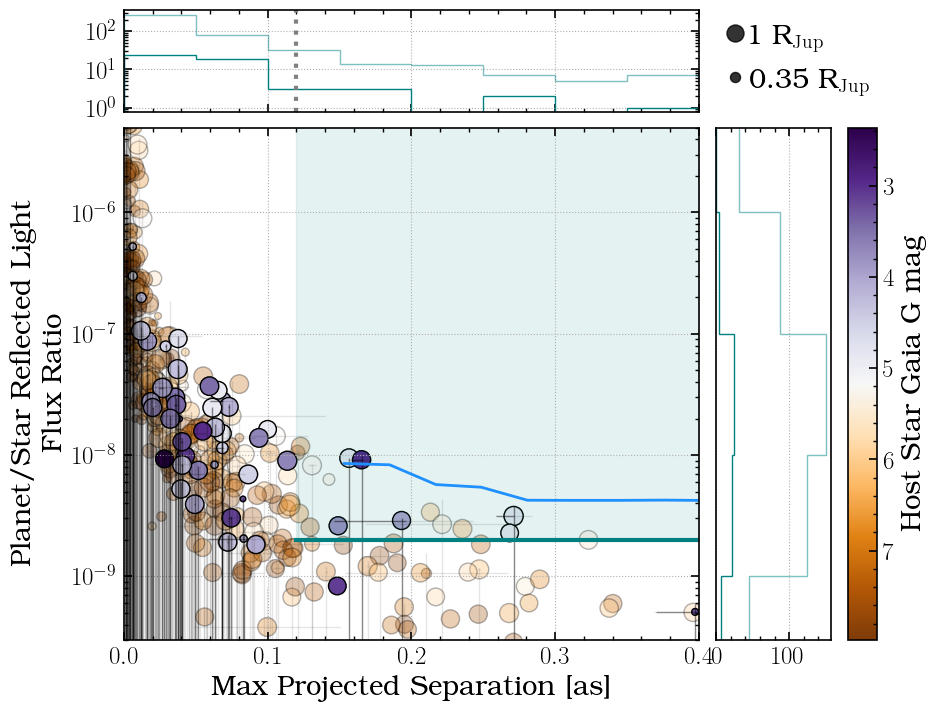

In [5]:
orbits = pd.read_csv('Target-list-with-orbital-params-variable-inc-alb.csv')

import matplotlib
cmap = matplotlib.colormaps.get_cmap('PuOr_r')
colors = cmap(np.linspace(0,0.9,5))

import matplotlib as mpl

ind = np.where((np.array(orbits['sy_gaiamag']) < 5) 
              )[0]

gmt_lod = 0.2063 * 0.63 / 24.5
laz_lod = 0.2063 * 0.63 / 3
rom_lod = 0.2063 * 0.63 / 2.4

# Plot max projected separation in GMT lambda/D
plotx = np.array(orbits['MaxProjectedSeparation_mas']) / 1000 #* gmt_lod/laz_lod
# vs Contrast at that separation:
# I computed this at Ag = 0.3 but I want to publish it at 0.45
ploty = np.array(orbits['ContrastAtMaxProj']) 
# Pull out relevant parameters:
rad = np.array(orbits['PlanetRadiuse']) * u.Rearth.to(u.Rjup)
#spt = np.array(orbits['SpT Number'])[ind]
phases = np.array(orbits['PhaseAtMaxProj'])
sepau = np.array(orbits['MaxProjectedSeparation_au'])
sepmas = np.array(orbits['MaxProjectedSeparation_mas'])
starteff = np.array(orbits['StarTeff'])
starmag = np.array(orbits['sy_gaiamag'])

ind2 = np.where((np.array(orbits['sy_gaiamag']) < 8) 
              )[0]

# set some things for the plot:
xaxis_label = r'\[ \mathrm{Max\; Projected\; Separation}\; [as]\]'
annotation_text = r"$$\mathrm{For}\; i'\; filter, \;D = 25.4m\$$"
output_file_name = 'TargetList-GMagAOX-Max-separation-contrast'

# normalize colors:
colorby = starmag
cbartitle = 'Host Star Gaia G mag'
markersizeby = rad


markermultiple = 150

# set up figure:
fig = plt.figure(figsize=(10,8))
ax = fig.add_gridspec(top=0.75, right=0.7).subplots()
# a = ax.scatter(plotx, ploty, 
#             c=phases, cmap='seismic', s=rad*15, alpha =0.7, norm=norm, edgecolor='black')
norm = mpl.colors.Normalize(vmin=min(colorby[ind2]), vmax=np.max(colorby[ind2]))

a2 = ax.scatter(plotx[ind2], ploty[ind2], 
            c=colorby[ind2], cmap=cmap, s=markersizeby[ind2]*markermultiple, alpha = 0.3, norm=norm, edgecolor='black')

a = ax.scatter(plotx[ind], ploty[ind], 
            c=colorby[ind], cmap=cmap, s=markersizeby[ind]*markermultiple, alpha = 1, norm=norm, edgecolor='black')


dx_up = np.abs(np.array(orbits['MaxProjectedSeparation_mas_inc90'])[ind]/1000 - np.array(orbits['MaxProjectedSeparation_mas'])[ind] / 1000)
dx_down = np.abs(np.array(orbits['MaxProjectedSeparation_mas'])[ind] / 1000 - np.array(orbits['MaxProjectedSeparation_mas_inc10'])[ind]/1000)

dy_up = np.abs(np.array(orbits['ContrastAtMaxProj'][ind]) * 0.45/0.3 - np.array(orbits['ContrastAtMaxProj_inc10_alb07'])[ind] )
dy_down = np.abs(np.array(orbits['ContrastAtMaxProj'][ind]) * 0.45/0.3 - np.array(orbits['ContrastAtMaxProj_inc10_alb01'])[ind] )

ax.errorbar(plotx[ind], ploty[ind],
             xerr = [dx_down, dx_up], yerr = [dy_down, dy_up],
             ls = 'None', ecolor='black', elinewidth=1, alpha=0.4
             )


dx_up = np.abs(np.array(orbits['MaxProjectedSeparation_mas_inc90'])[ind2]/1000 - np.array(orbits['MaxProjectedSeparation_mas'])[ind2] / 1000)
dx_down = np.abs(np.array(orbits['MaxProjectedSeparation_mas'])[ind2] / 1000 - np.array(orbits['MaxProjectedSeparation_mas_inc10'])[ind2]/1000)

dx_up = np.abs(np.array(orbits['MaxProjectedSeparation_mas_inc90'])[ind2]/1000 - np.array(orbits['MaxProjectedSeparation_mas_inc10'])[ind2]/1000)
dx_down = dx_up


dy_up = np.abs(np.array(orbits['ContrastAtMaxProj'][ind2]) * 0.45/0.3 - np.array(orbits['ContrastAtMaxProj_inc10_alb07'])[ind2] )
dy_down = np.abs(np.array(orbits['ContrastAtMaxProj'][ind2]) * 0.45/0.3 - np.array(orbits['ContrastAtMaxProj_inc10_alb01'])[ind2] )
ax.errorbar(plotx[ind2], ploty[ind2],
             xerr = [dx_down, dx_up], yerr = [dy_down, dy_up],
             ls = 'None', ecolor='black', elinewidth=1, alpha = 0.1
             )
xlim=0.4
ylim = 5e-6
x,y = xlim + 0.025, 3e-5
ax.scatter(x,y, s = 1*markermultiple, color='black', alpha = 0.8, clip_on=False)
ax.annotate('1 R$_{\\mathrm{Jup}}$', xy = (0.6,0.85), xytext = (0.75,0.835), xycoords='figure fraction',fontsize=20, clip_on=False)

x,y = xlim + 0.025, 1.3e-5
ax.scatter(x,y, s = 0.35*markermultiple, color='black', alpha = 0.8, clip_on=False)
ax.annotate('0.35 R$_{\\mathrm{Jup}}$', xy = (0.6,0.85), xytext = (0.75,0.78), xycoords='figure fraction',fontsize=20, clip_on=False)
# ax.scatter(x,y, s = 0.35*markermultiple, color='black', alpha = 0.8)
# ax.annotate('0.35 R$_{\\mathrm{Jup}}$', xy = (x,y), xytext = (15,-5), textcoords='offset points',fontsize=20)


# ax.annotate(r' For A$_g$ = 0.45, $\lambda$ = 0.63$\mu$m', 
#             xy = (0.5,0.9), xycoords = ('axes fraction'),
#             fontsize=15)

#ax.axvline(x=2.7, color='grey',ls=':')


ax.set_yscale('log')
ax.set_xlim(0,0.4)
ax.set_ylim(bottom=3e-10, top=5e-6)

ax.set_xlabel(r'Max Projected Separation [as]')
ax.set_ylabel('Planet/Star Reflected Light \n Flux Ratio')
ax.grid(ls=':')


ax.plot([0.12, 0.42],[2e-9,2e-9], color='teal')
# ax.plot([0.12, 0.42],[1e-7,1e-7], color='black')
ax.fill_between([0.12, 0.42], [2e-9,2e-9], [1,1], color='teal', alpha=0.1)


cons_mode = '_opti'
datapath = '/Users/lapearce/Dropbox/astro_packages/ReflectedLightPlanetsPlot/'
fname = datapath+'Roman_pred_imaging_long'+cons_mode+'.txt'
from astropy.io import ascii
d_tel = 2.4 * u.m
dat = ascii.read(fname)
dat['lambda'].unit = u.nm
dat['contr_snr5'] = dat['contr']*5/dat['SNR']
dat['Rho(as)'] = dat['l/D'] * (dat['lambda'] / d_tel).decompose()*206265
cons_mode = '_cons'
fname = datapath+'Roman_pred_imaging_short'+cons_mode+'.txt'
from astropy.io import ascii
d_tel = 2.4 * u.m
dat2 = ascii.read(fname)
dat2['lambda'].unit = u.nm
dat2['contr_snr5'] = dat2['contr']*5/dat2['SNR']
dat2['Rho(as)'] = dat2['l/D'] * (dat2['lambda'] / d_tel).decompose()*206265
ax.plot(dat2['Rho(as)'], dat2['contr_snr5'], color='dodgerblue', linewidth=2, linestyle='-', label='')


#### Histograms:
ax1 = ax.inset_axes([0,1.03,1,0.2])#, sharex=ax)
ax1.hist(plotx[ind], histtype='step',lw=4, color='teal', bins=np.arange(0,int(max(plotx[ind])),0.05))
ax1.hist(plotx[ind2], histtype='step',lw=4, color='teal', bins=np.arange(0,int(max(plotx[ind])),0.05), alpha=0.5)
ax1.axvline(x=0.12, ls=':', color='grey')
ax1.grid(ls=':')
ax1.set_xlim(0,0.4)
ax1.set_yticks([0,100])
ax1.set_xticklabels([])
ax1.set_yscale('log')

ax2 = ax.inset_axes([1.03,0,0.2,1])
ax2.hist(np.log10(ploty[ind]), bins=np.arange(-10,-4,1), histtype='step',lw=4, color='teal',orientation="horizontal")
ax2.hist(np.log10(ploty[ind2]), bins=np.arange(-10,-4,1), histtype='step',lw=4, color='teal',orientation="horizontal", alpha=0.5)
ax2.set_ylim(bottom=np.log10(3e-10), top=np.log10(5e-6))
ax2.set_yticks([])
ax2.grid(ls=':')

import matplotlib as mpl
cmap = mpl.colormaps['PuOr_r']
norm = mpl.colors.Normalize(vmin=min(starmag[ind]), vmax=max(starmag[ind2]))
cbarax = ax.inset_axes([1.26,0,0.05,1])
fig.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cbarax, orientation="vertical")
cbarax.set_ylim(np.min(colorby[ind2]),np.max(colorby[ind2]))
cbarax.set_ylabel(cbartitle)
cbarax.invert_yaxis()


#plt.savefig('Lazuli-planets-lod-vs-fluxcont-variable-inc-alb.png', bbox_inches='tight')


## Planet scores and score charts

These csv's contain all planets in exoplanet archive which fell within IWA/OWA at any point in their mean orbits, separated by planets with inclination estimates, planets without, and planets selected for blue wavelength charaterization

In [ ]:
#IWA/OWA at 0.63 um
lod = 0.2063 * 0.63/3
IWA = 3 * lod
OWA20 = 20 * lod
OWA10 = 10 * lod

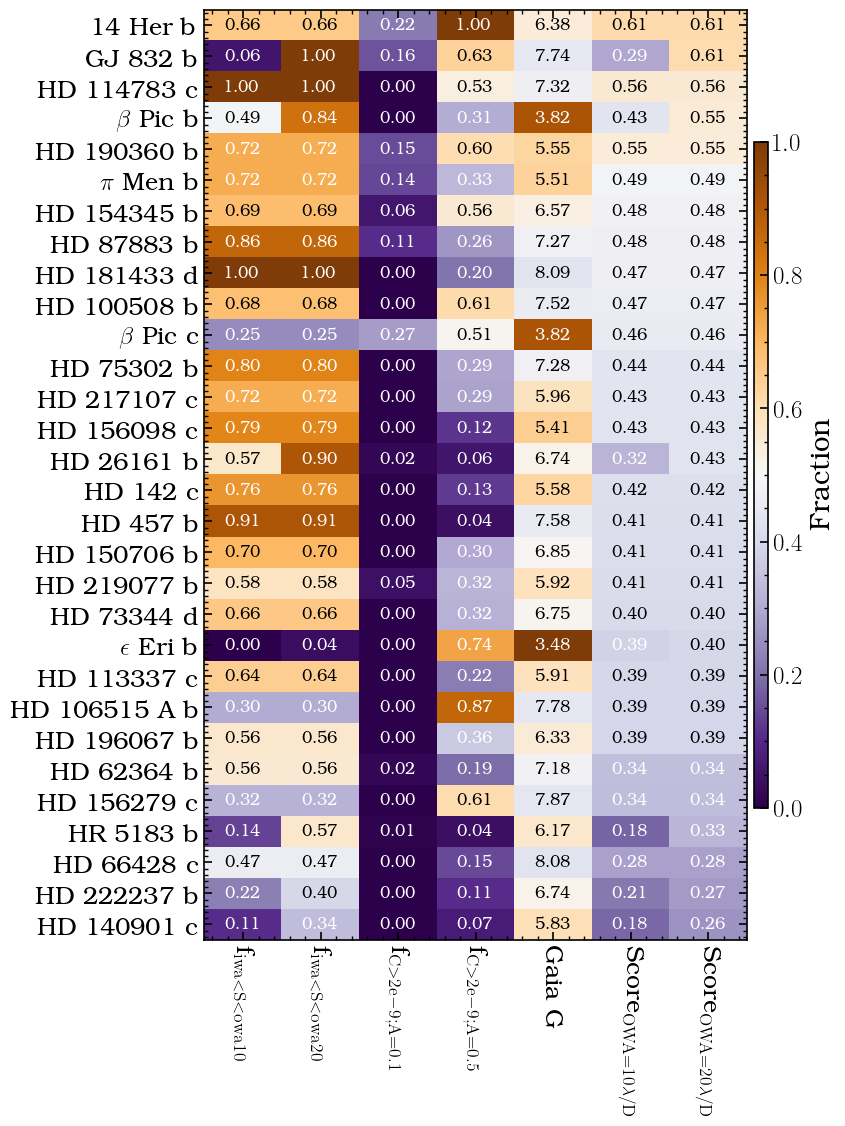

In [8]:
selected = pd.read_csv('Selected-wIncl.csv')

weights = [1,1,1.5,1]
score20 = (selected['FracContAboveMaxGoal_A0.1_inc60']*weights[0] + \
        selected['FracContAboveMaxGoal_A0.5_inc60']*weights[1] + \
        selected['FracWithinDetSep_A0.5_inc60']*weights[2] + 
         (1/selected['sy_gaiamag'])/max(1/selected['sy_gaiamag'])*weights[3]
        ) / sum(weights)

weights = [1,1,1.5,1]
score10 = (selected['FracContAboveMaxGoal_A0.1_inc60']*weights[0] + \
        selected['FracContAboveMaxGoal_A0.5_inc60']*weights[1] + \
        selected['FracWithinDetSep_OWA10_A0.5_inc60']*weights[2] + 
         (1/selected['sy_gaiamag'])/max(1/selected['sy_gaiamag'])*weights[3]
        ) / sum(weights)

selected['score_OWA10'] = score10
selected['score_OWA20'] = score20


selected_sort = selected.loc[np.argsort(score20)[::-1]]

im = np.zeros((len(selected),7))
magnum = []
#for i in range(len(selected)):
for i,j in enumerate(np.argsort(score20)[::-1]):
    im[i,0] = selected_sort.loc[j,'FracWithinDetSep_OWA10_A0.5_inc60']
    im[i,1] = selected_sort.loc[j,'FracWithinDetSep_A0.5_inc60']
    im[i,2] = selected_sort.loc[j,'FracContAboveMaxGoal_A0.1_inc60']
    im[i,3] = selected_sort.loc[j,'FracContAboveMaxGoal_A0.5_inc60']
    im[i,4] = (1/selected_sort.loc[j,'sy_gaiamag'])/max(1/selected['sy_gaiamag'])
    im[i,5] = selected_sort.loc[j,'score_OWA10']
    im[i,6] = selected_sort.loc[j,'score_OWA20']
    magnum.append(selected.loc[j,'sy_gaiamag'])

inds = np.argsort(score20)[::-1]

fig,ax = plt.subplots(figsize = (7,18))
#ax.set_title('Planets with literature inclination')

a = ax.imshow(im, origin='upper', cmap='PuOr_r')
cax = fig.add_axes([0.91,0.31,0.02,0.37])
cbar = plt.colorbar(a, cax=cax)
cax.set_ylabel('Fraction')
ax.set_aspect(0.4)
yticks = np.arange(0,len(selected),1)
ylabels = [name.replace('eps','$\\epsilon$').replace('bet','$\\beta$').replace('pi','$\\pi$') for name in selected_sort['pl_name']]
ax.set_yticks(yticks,ylabels)

xlabels= ['f$_{\\mathrm{iwa<S<owa10}}$', 'f$_{\\mathrm{iwa<S<owa20}}$', 
         'f$_{\\mathrm{C>2e-9;A=0.1}}$', 'f$_{\\mathrm{C>2e-9;A=0.5}}$', 'Gaia G',
         'Score$_{\\mathrm{OWA=10\\lambda/D}}$','Score$_{\\mathrm{OWA=20\\lambda/D}}$']
ax.set_xticks(np.arange(0,im.shape[1],1),xlabels, rotation=-90)

for i in range(len(selected)):
    for j in range(im.shape[1]):
        if im[i,j] > 0.39 and im[i,j] <= 0.7:
            color = 'black'
        else:
            color='white'
        if j == 4:
            ax.annotate('{:.2f}'.format(magnum[i]), xy=(j,i), ha='center', va='center', color=color, fontsize=12)
        else:
            ax.annotate('{:.2f}'.format(im[i,j]), xy=(j,i), ha='center', va='center', color=color, fontsize=12)

#plt.savefig('targets-with-inc-fraction-chart-sorted-by-score.png',bbox_inches='tight')

## Here we are importing the dictionary of planet orbital solutions from GRIP (www.getagrip.space) and pulling out the ones from our target list.

In [9]:
from orbitdict import *

## Here are the planets we selected with inclintion estimates from the above score analysis:

In [10]:
planetsinc = [
    '14 Her b','GJ 832 b','HD 114783 c', 'HD 190360 b', 'bet Pic b', 'HD 154345 b', 'HD 87883 b', 'pi Men b',
    'HD 100508', 'bet Pic c', 'eps Eri b'
]
planetsnoinc = ['gamma Cep b', 'ups And d', '47 UMa b', '47 UMa c', 'HD 160691 c']
keys = planetsinc

ind = []
plkeys = []
for key in keys:
    i = np.where(selected['pl_name'] == key)[0]
    if len(i) > 0:
        ind.append(i[0])
        plkeys.append(key)

## Repeat score analysis for planets without inclination

In [14]:
selected2 = pd.read_csv('Selected-woutIncl.csv')
selected2 = selected2.loc[np.argsort(selected2['sy_gaiamag'])]
selected2 = selected2.reset_index(drop=True)

weights = [1]*12
for i in range(3):
    weights[i] = 1.5
score20 = selected2['FracWithinDetSep_A0.5_inc10']*weights[0] + \
    selected2['FracWithinDetSep_A0.5_inc60']*weights[1] + \
    selected2['FracWithinDetSep_A0.5_inc90']*weights[2] + \
    selected2['FracContAboveMaxGoal_A0.1_inc10']*weights[7] + \
    selected2['FracContAboveMaxGoal_A0.1_inc90']*weights[8] + \
    selected2['FracContAboveMaxGoal_A0.5_inc10']*weights[9] + \
    selected2['FracContAboveMaxGoal_A0.5_inc90']*weights[10] + \
    (1/selected2['sy_gaiamag'])/max(1/selected2['sy_gaiamag'])*weights[11]
score20 = score20 / sum(weights)
selected2['score_OWA20'] = score20

weights = [1]*12
for i in range(3):
    weights[i] = 1.5
score10 = selected2['FracWithinDetSep_OWA10_A0.5_inc10']*weights[0] + \
    selected2['FracWithinDetSep_OWA10_A0.5_inc60']*weights[1] + \
    selected2['FracWithinDetSep_OWA10_A0.5_inc90']*weights[2] + \
    selected2['FracContAboveMaxGoal_A0.1_inc10']*weights[7] + \
    selected2['FracContAboveMaxGoal_A0.1_inc90']*weights[8] + \
    selected2['FracContAboveMaxGoal_A0.5_inc10']*weights[9] + \
    selected2['FracContAboveMaxGoal_A0.5_inc90']*weights[10] + \
    (1/selected2['sy_gaiamag'])/max(1/selected2['sy_gaiamag'])*weights[11]
score10 = score10 / sum(weights)
selected2['score_OWA10'] = score10


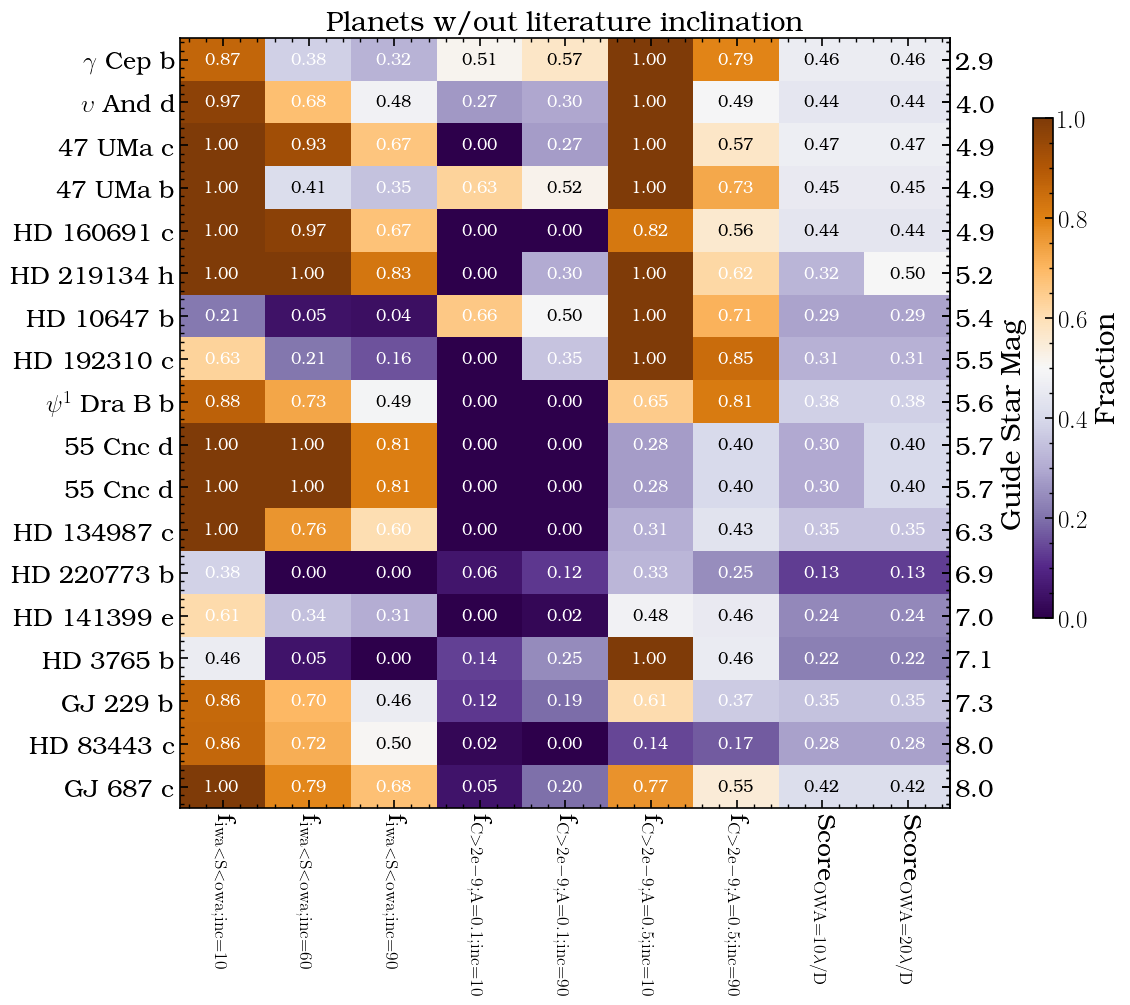

In [16]:


im = np.zeros((len(selected2),9))
for i in range(len(selected2)):
    im[i,0] = selected2.loc[i,'FracWithinDetSep_A0.5_inc10']
    im[i,1] = selected2.loc[i,'FracWithinDetSep_A0.5_inc60']
    im[i,2] = selected2.loc[i,'FracWithinDetSep_A0.5_inc90']
    im[i,3] = selected2.loc[i,'FracContAboveMaxGoal_A0.1_inc10']
    im[i,4] = selected2.loc[i,'FracContAboveMaxGoal_A0.1_inc90']
    im[i,5] = selected2.loc[i,'FracContAboveMaxGoal_A0.5_inc10']
    im[i,6] = selected2.loc[i,'FracContAboveMaxGoal_A0.5_inc90']
    im[i,7] = selected2.loc[i,'score_OWA10']
    im[i,8] = selected2.loc[i,'score_OWA20']

fig,ax = plt.subplots(figsize = (10,10))
ax.set_title('Planets w/out literature inclination')
a = ax.imshow(im, origin='upper', cmap='PuOr_r')
cax = fig.add_axes([0.98,0.3,0.02,0.5])
cbar = plt.colorbar(a, cax=cax)
cax.set_ylabel('Fraction')
ax.set_aspect(0.5)
yticks = np.arange(0,len(selected2),1)
ylabels = [name.replace('gam','$\\gamma$').replace('ups','$\\upsilon$').replace('psi1','$\\psi^{1}$') for name in selected2['pl_name']]
ax.set_yticks(yticks,ylabels)
# ax2 = ax.twinx()
ax2 = ax.secondary_yaxis('right')
ylabels = ['{:.1f}'.format(selected2.loc[i,'sy_gaiamag']) for i in range(len(selected2))]
ax2.set_yticks(yticks,ylabels)
ax2.set_ylabel('Guide Star Mag')
xlabels= ['f$_{\\mathrm{iwa<S<owa;inc=10}}$',
          'f$_{\\mathrm{iwa<S<owa;inc=60}}$',
          'f$_{\\mathrm{iwa<S<owa;inc=90}}$',
         'f$_{\\mathrm{C>2e-9;A=0.1;inc=10}}$',
         'f$_{\\mathrm{C>2e-9;A=0.1;inc=90}}$',
         'f$_{\\mathrm{C>2e-9;A=0.5;inc=10}}$',
         'f$_{\\mathrm{C>2e-9;A=0.5;inc=90}}$',
          'Score$_{\\mathrm{OWA=10\\lambda/D}}$',
          'Score$_{\\mathrm{OWA=20\\lambda/D}}$']
ax.set_xticks(np.arange(0,im.shape[1],1),xlabels, rotation=-90)

for i in range(len(selected2)):
    for j in range(im.shape[1]):
        if im[i,j] > 0.39 and im[i,j] <= 0.6:
            color = 'black'
        else:
            color='white'
        ax.annotate('{:.2f}'.format(im[i,j]), xy=(j,i), ha='center', va='center', color=color, fontsize=12)
        
#plt.savefig('targets-wout-inc-fraction-chart.png',bbox_inches='tight')


# Bluer targets

In [18]:
blue= pd.read_csv('Selected-blue.csv')
# Let's downselect to only deal with the best targets:
blue=blue.loc[np.where(blue['score'] > 0.4)[0]]
blue = blue.reset_index(drop=True)

In [23]:
ind = []
blueselect = ['HD 192310 c', #'HD 147513 b', - controversial in Exo Archive
        'HD 128311 c', 'HD 10647 b', '7 CMa b', 'HD 164922 b', 'HD 216437 b', '7 CMa c',
       'HD 219134 h', 'HD 70642 b', #'GJ 687 c', - can't get good oribt sim and it has faint guide star anyway
              'HD 160691 b', 'psi1 Dra B b']
for name in blueselect:
    print(name)
    ind.append(np.where(blue['pl_name'] == name)[0][0])

blueselect = blue.loc[ind]
blueselect = blueselect.sort_values('score', ascending=False)
blueselect = blueselect.reset_index(drop=True)

weights = [1]*12
for i in range(3):
    weights[i] = 1.5
score20 = blueselect['FracWithinDetSep_A0.5_inc10']*weights[0] + \
    blueselect['FracWithinDetSep_A0.5_inc60']*weights[1] + \
    blueselect['FracWithinDetSep_A0.5_inc90']*weights[2] + \
    blueselect['FracContAboveMaxGoal_A0.1_inc10']*weights[7] + \
    blueselect['FracContAboveMaxGoal_A0.1_inc90']*weights[8] + \
    blueselect['FracContAboveMaxGoal_A0.5_inc10']*weights[9] + \
    blueselect['FracContAboveMaxGoal_A0.5_inc90']*weights[10] + \
    (1/blueselect['sy_gaiamag'])/max(1/blueselect['sy_gaiamag'])*weights[11]
score20 = score20 / sum(weights)
blueselect['score'] = score20
# This is a close-in set of planets so the different OWA will not affect the results

#blueselect

HD 192310 c
HD 128311 c
HD 10647 b
7 CMa b
HD 164922 b
HD 216437 b
7 CMa c
HD 219134 h
HD 70642 b
HD 160691 b
psi1 Dra B b


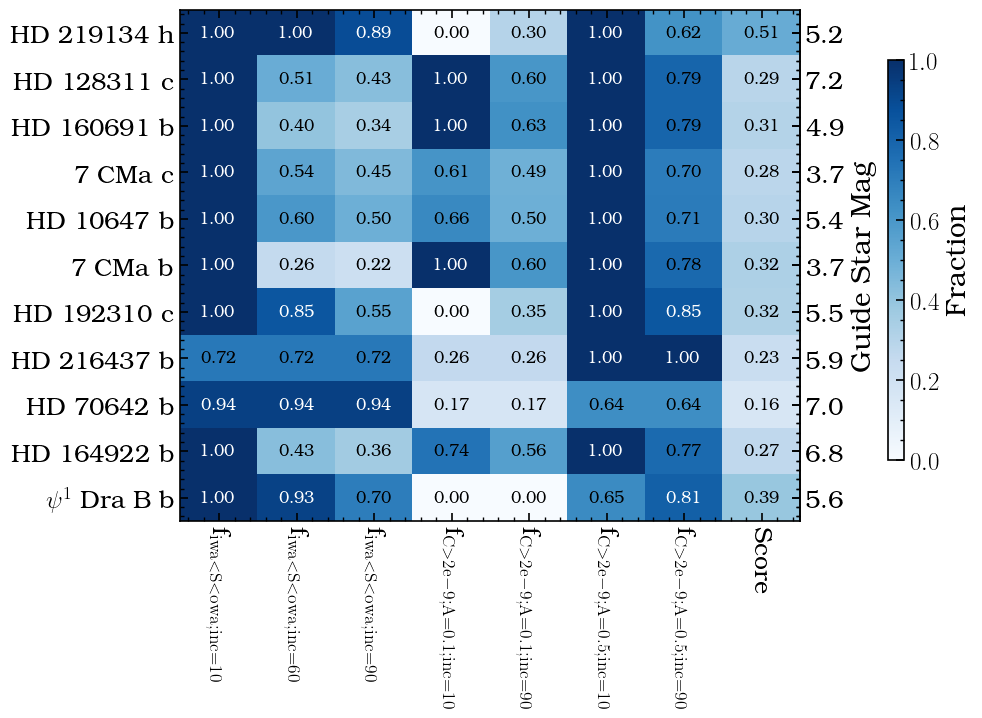

In [24]:


im = np.zeros((len(blueselect),8))
for i in range(len(blueselect)):
    im[i,0] = blueselect.loc[i,'FracWithinDetSep_A0.5_inc10_blue']
    im[i,1] = blueselect.loc[i,'FracWithinDetSep_A0.5_inc60_blue']
    im[i,2] = blueselect.loc[i,'FracWithinDetSep_A0.5_inc90_blue']
    im[i,3] = blueselect.loc[i,'FracContAboveMaxGoal_A0.1_inc10']
    im[i,4] = blueselect.loc[i,'FracContAboveMaxGoal_A0.1_inc90']
    im[i,5] = blueselect.loc[i,'FracContAboveMaxGoal_A0.5_inc10']
    im[i,6] = blueselect.loc[i,'FracContAboveMaxGoal_A0.5_inc90']
    im[i,7] = blueselect.loc[i,'score']

fig,ax = plt.subplots(figsize = (8,10))
ax.set_title('')
a = ax.imshow(im, origin='upper', cmap='Blues')
cax = fig.add_axes([1.01,0.3,0.02,0.4])
cbar = plt.colorbar(a, cax=cax)
cax.set_ylabel('Fraction')
ax.set_aspect(0.6)
yticks = np.arange(0,len(blueselect),1)
ylabels = [name.replace('gam','$\\gamma$').replace('ups','$\\upsilon$').replace('psi1','$\\psi^{1}$') for name in blueselect['pl_name']]
ax.set_yticks(yticks,ylabels)
# ax2 = ax.twinx()
ax2 = ax.secondary_yaxis('right')
ylabels = ['{:.1f}'.format(blueselect.loc[i,'sy_gaiamag']) for i in range(len(blueselect))]
ax2.set_yticks(yticks,ylabels)
ax2.set_ylabel('Guide Star Mag')
# xlabels= ['f$_{\\mathrm{iwa<S<owa}}$', 'f$_{\\mathrm{C>1e-7;A=0.1}}$', 'f$_{\\mathrm{C>1e-7;A=0.45}}$',
#          'f$_{\\mathrm{C>2e-9;A=0.1}}$', 'f$_{\\mathrm{C>2e-9;A=0.45}}$',
#          'score']
xlabels= ['f$_{\\mathrm{iwa<S<owa;inc=10}}$',
          'f$_{\\mathrm{iwa<S<owa;inc=60}}$',
          'f$_{\\mathrm{iwa<S<owa;inc=90}}$',
         'f$_{\\mathrm{C>2e-9;A=0.1;inc=10}}$',
         'f$_{\\mathrm{C>2e-9;A=0.1;inc=90}}$',
         'f$_{\\mathrm{C>2e-9;A=0.5;inc=10}}$',
         'f$_{\\mathrm{C>2e-9;A=0.5;inc=90}}$',
         'Score']
ax.set_xticks(np.arange(0,im.shape[1],1),xlabels, rotation=-90)

for i in range(len(blueselect)):
    for j in range(im.shape[1]):
        if im[i,j] > 0.8 :
            color = 'white'
        else:
            color='black'
        ax.annotate('{:.2f}'.format(im[i,j]), xy=(j,i), ha='center', va='center', color=color, fontsize=12)



#plt.savefig('targets-bluer.png',bbox_inches='tight')

In [ ]:
# blueselect.to_csv('Selected-blue.csv', index=False)
# selected.to_csv('Selected-wIncl.csv', index=False)
# selected2.to_csv('Selected-woutIncl.csv', index=False)

# Put together

In [26]:
selected = pd.read_csv('Selected-wIncl.csv')
selected2 = pd.read_csv('Selected-woutIncl.csv')
blueselect = pd.read_csv('Selected-blue.csv')

# Selected inc targets:
planetsinc = [
    '14 Her b','GJ 832 b','HD 114783 c', 'HD 190360 b', 'bet Pic b', 'HD 154345 b', 'HD 87883 b', 'pi Men b',
    'HD 100508 b', 'bet Pic c', 'eps Eri b'
]
# selected no inc targets:
planetsnoinc = ['gam Cep b', 'ups And d', '47 UMa b', '47 UMa c', 'HD 160691 c']
planetsblue = ['HD 192310 c', #'HD 147513 b', - controversial in Exo Archive
        'HD 128311 c', 'HD 10647 b', '7 CMa b', 'HD 164922 b', 'HD 216437 b', '7 CMa c',
       'HD 219134 h', 'HD 70642 b', #'GJ 687 c', 
               'HD 160691 b', 'psi1 Dra B b']

ind = []
for name in planetsinc:
    ind.append(np.where(selected['pl_name'] == name)[0][0])
selected = selected.loc[ind]
selected = selected.reset_index(drop = True)

ind = []
for name in planetsnoinc:
    ind.append(np.where(selected2['pl_name'] == name)[0][0])
selected2 = selected2.loc[ind]
selected2 = selected2.reset_index(drop = True)


keys = planetsinc + planetsnoinc + planetsblue
names = []
for key in keys:
    name = key.replace('pi','$\\pi$').replace('bet','$\\beta$').replace('ups','$\\upsilon$')\
            .replace('eps','$\\epsilon$').replace('gam','$\\gamma$').replace('psi1','$\\psi^1$')
    names.append(name)
    
starnames = [key[:-2] for key in names]
selected = pd.concat([selected, selected2, blueselect])
selected = selected.reset_index(drop=True)
ind = []
plkeys = []
for key in keys:
    i = np.where(selected['pl_name'] == key)[0]
    print(key, i)
    if len(i) > 0:
        ind.append(i[0])
        plkeys.append(key)


14 Her b [0]
GJ 832 b [1]
HD 114783 c [2]
HD 190360 b [3]
bet Pic b [4]
HD 154345 b [5]
HD 87883 b [6]
pi Men b [7]
HD 100508 b [8]
bet Pic c [9]
eps Eri b [10]
gam Cep b [11]
ups And d [12]
47 UMa b [13]
47 UMa c [14]
HD 160691 c [15]
HD 192310 c [22]
HD 128311 c [17]
HD 10647 b [20]
7 CMa b [21]
HD 164922 b [25]
HD 216437 b [23]
7 CMa c [19]
HD 219134 h [16]
HD 70642 b [24]
HD 160691 b [18]
psi1 Dra B b [26]


In [28]:
targets = selected.loc[ind]
targets = targets.reset_index(drop=True)
i = 0
targets.loc[i,'pl_name'][:-2]


'14 Her'

In [ ]:
# Get Gaia source ids for selected host stars:

import re
from astroquery.simbad import Simbad

custom_simbad = Simbad()
custom_simbad.add_votable_fields("ids")
sourceids = []
for i in range(len(targets)):
    result = custom_simbad.query_object(targets.loc[i,'pl_name'][:-2])
    ids = result["ids"][0]
    if isinstance(ids, bytes):
        ids = ids.decode()
    
    match = re.search(r"Gaia DR3 (\d+)", ids)
    
    if match:
        gaia_source_id = int(match.group(1))
        print(i,targets.loc[i,'pl_name'],gaia_source_id)
        sourceids.append(gaia_source_id)
    else:
        sourceids.append(np.nan)
targets['sourceid'] = sourceids

0 14 Her b 1385293808145621504
1 GJ 832 b 6562924609150908416
2 HD 114783 c 3684934540986187776
3 HD 190360 b 2029433521248546304
4 bet Pic b 4792774797545800832
5 HD 154345 b 1359938520253565952
6 HD 87883 b 747266452000257280
7 pi Men b 4623036865373793408
8 HD 100508 b 5236623864770649600
9 bet Pic c 4792774797545800832
10 eps Eri b 5164707970261890560
11 gam Cep b 2281778105594488192
12 ups And d 348020482735930112
13 47 UMa b 777254360337133312
14 47 UMa c 777254360337133312
15 HD 160691 c 5945941905576552064
16 HD 192310 c 6847167606385195648
17 HD 128311 c 1176209886733406592
18 HD 10647 b 4912580642524184960
19 7 CMa b 2939555954755196160
20 HD 164922 b 4582680493669880704
21 HD 216437 b 6384510877400590336
22 7 CMa c 2939555954755196160
23 HD 219134 h 2009481748875806976
24 HD 70642 b 5540006949934104448
25 HD 160691 b 5945941905576552064
26 psi1 Dra B b 1651268763282397312


In [ ]:
# Query Gaia archive for Gaia stuff:
targets['gaia G'] = np.nan
targets['gaia bp'] = np.nan
targets['gaia rp'] = np.nan
targets['bp_rp'] = np.nan
targets['gaia_plx'] = np.nan
targets['gaia_plx_err'] = np.nan
targets['ra'] = np.nan
targets['dec'] = np.nan
from astroquery.gaia import Gaia
for i in range(len(targets)):
    print(i)
    sourceid = sourceids[i]
    # Gaia TAP query
    query = f"""
    SELECT *
    FROM gaiadr3.gaia_source
    WHERE source_id = {sourceid}
    """
    
    job = Gaia.launch_job(query)
    gaia_result = job.get_results()
    targets.loc[i,'gaia G'] = gaia_result['phot_g_mean_mag']
    targets.loc[i,'gaia bp'] = gaia_result['phot_bp_mean_mag']
    targets.loc[i,'gaia rp'] = gaia_result['phot_rp_mean_mag']
    targets.loc[i,'bp_rp'] = gaia_result['bp_rp']
    targets.loc[i,'gaia_plx'] = gaia_result['parallax']
    targets.loc[i,'gaia_plx_err'] = gaia_result['parallax_error']
    targets.loc[i,'ra'] = gaia_result['ra']
    targets.loc[i,'dec'] = gaia_result['dec']


In preparation for Gaia DR4, the Gaia archive is in evolution. Unfortunately, it may be unstable at times and particular types of queries may time out. Please consider registering for a user account (https://www.cosmos.esa.int/web/gaia-users/register). For questions or advice, please contact the Gaia helpdesk (https://www.cosmos.esa.int/web/gaia/gaia-helpdesk).
0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26


# Figures for analysing the target list:

In [32]:
targets = pd.read_csv('targets.csv')

In [29]:
keys = targets['pl_name']
names = []
for key in keys:
    name = key.replace('pi','$\\pi$').replace('bet','$\\beta$').replace('ups','$\\upsilon$')\
            .replace('eps','$\\epsilon$').replace('gam','$\\gamma$').replace('psi1','$\\psi^1$')
    names.append(name)
    
starnames = [key[:-2] for key in names]

In [34]:
import matplotlib as mpl
def add_interval(ax, xdata, ydata, caps="  ", color = 'None', textcolor = 'None'):
    import matplotlib as mpl
    if color == 'None':
        line = ax.add_line(mpl.lines.Line2D(xdata, ydata,lw=3))
    else:
        line = ax.add_line(mpl.lines.Line2D(xdata, ydata,lw=3, color=color))
    if textcolor == 'None':
        textcolor = line.get_color()
    anno_args = {
        'ha': 'center',
        'va': 'center',
        'size': 8,
        'color': textcolor
    }
    a0 = ax.annotate(caps[0], xy=(xdata[0], ydata[0]),  **anno_args)
    a1 = ax.annotate(caps[1], xy=(xdata[1], ydata[1]), **anno_args)
    return (line,(a0,a1))




<>:19: SyntaxWarning: invalid escape sequence '\m'
<>:19: SyntaxWarning: invalid escape sequence '\m'
/var/folders/jg/989ldvh91l31v90slbnhd8x80000gr/T/ipykernel_1319/3511553008.py:19: SyntaxWarning: invalid escape sequence '\m'
  cbar.ax.set_ylabel('T$_\mathrm{eff}$ [K]', fontsize=20)


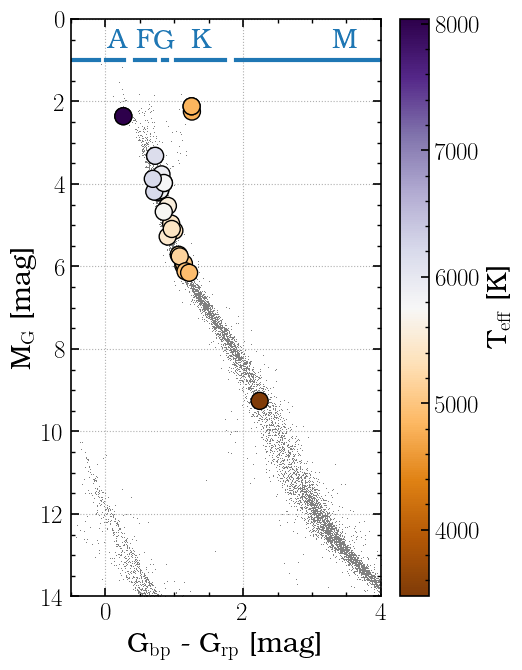

In [35]:
# See Pearce et al. 2025 for details on how these files were constructed:
g = pd.read_csv('Gaiacmdinput.csv')
import pickle
Dict = pickle.load(open(
    'everything-to-make-target-list-cmd.pkl','rb'))
ranges = Dict['ranges']
types = Dict['types']


fig,ax = plt.subplots(figsize=(5,7.5))
ax.plot(g['bp_rp'],
            g['phot_g_mean_mag'] - 5*np.log10(1000/g['parallax']) + 5,
            marker=',', ls='None', color='grey'
           )

a = ax.scatter(targets['bp_rp'], targets['gaia G'] - 5*np.log10(1000/targets['gaia_plx']) + 5, zorder=10, s=150, 
           c=targets['StarTeff'], cmap='PuOr', edgecolors='black')
cbar = plt.colorbar(a)
cbar.ax.set_ylabel('T$_\mathrm{eff}$ [K]', fontsize=20)
ax.invert_yaxis()
y = 1
for i in range(2,7):
#i = 3
    r = [float(ranges[i][j]) for j in range(len(ranges[i]))]

    add_interval(ax, [min(r)+0.05,max(r)-0.05], (y,y), "  ",color='tab:blue')
    ax.annotate(types[i],xy=(np.mean([min(r),max(r)]),y-0.3), ha='center',color='tab:blue', fontsize=20)
    #ax.set_ylim(top=-2.5)
i = 2
r = [float(ranges[i][j]) for j in range(len(ranges[i]))]
add_interval(ax, [-1,min(r)-0.05], (y,y), "  ",color='tab:blue')
#ax.annotate('OB',xy=(-0.5,y-0.3), ha='center',color='tab:blue', fontsize=20)


ax.set_xlabel('G$_\\mathrm{bp}$ - G$_\\mathrm{rp}$ [mag]')
ax.set_ylabel('M$_\\mathrm{G}$ [mag]')
ax.set_ylim(bottom=14, top = 0)
ax.set_xlim(-0.5,4)
ax.grid(ls=':')
plt.savefig('star-cmd.png', bbox_inches='tight')

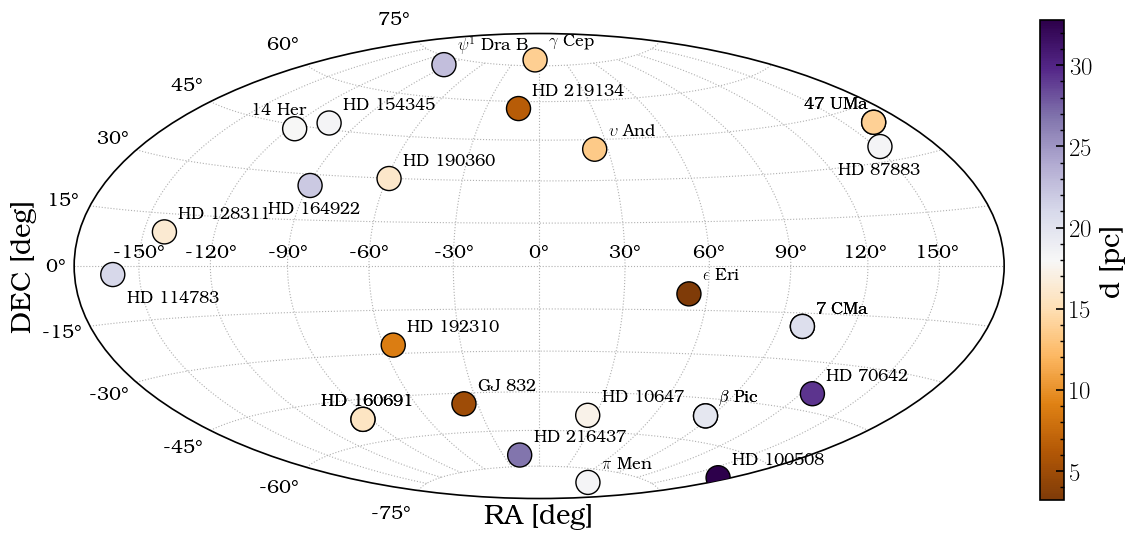

In [37]:
#fig,ax = plt.subplots(figsize=(8,8))
fig=plt.figure(figsize=(12,12))
ax = plt.subplot(projection="hammer")

# x_rad1 = np.radians(np.where(g['ra'] > 180, g['ra'] - 360, g['ra']))
# ax.plot(x_rad1,
#         np.radians(g['dec']),
#             marker=',', ls='None', color='grey'
#            )

x_rad = np.radians(np.where(targets['ra'] > 180, targets['ra'] - 360, targets['ra']))
a = ax.scatter(x_rad, np.radians(targets['dec']), zorder=10, s=300, 
           c=1000/targets['gaia_plx'], cmap='PuOr', edgecolors='black')

# anDict = {
#     '47 UMa':[-90,10],
#     'HD 87883':[-50,-25],
#     'HD 75302':[-50, -25],
#     '$\\epsilon$ Eri':[-50,-15],
#     '$\\beta$ Pic':[0,10],
#     '$\\pi$ Men':[-15,10],
#     'GJ 832':[-5,15],
#     'HD 160691':[-50,-25],
#     'HD 114783':[-10,-25],
#     'HD 190360':[-50,-25],
#     '14 Her':[-40,-25],
#     'HD 154345':[-15,15],
#     '$\\upsilon$ And':[5,-15],
#     '$\\gamma$ Cep':[5,-15]
# }
anDict = {}
for name in starnames:
    anDict.update({name:[10,10]})
anDict.update({'14 Her':[-30,10]})
anDict.update({'47 UMa':[-50,10]})
anDict.update({'HD 87883':[-30,-20]})
anDict.update({'HD 164922':[-30,-20]})
anDict.update({'HD 114783':[10,-20]})
anDict.update({'HD 160691':[-30,10]})

for i in range(len(targets)):
    pos = anDict[starnames[i]]
    ax.annotate(starnames[i], xy=(x_rad[i],
                          np.radians( np.array(targets['dec'])[i])), 
                                         xytext = (pos[0],pos[1]), textcoords = 'offset points', fontsize = 12)
cax = fig.add_axes([0.93,0.3,0.02,0.4])
cbar = plt.colorbar(a, cax=cax)
cbar.ax.set_ylabel('d [pc]', fontsize=20)



ax.set_xlabel('RA [deg]')
ax.set_ylabel('DEC [deg]')
ax.tick_params(axis='both', labelsize=14)
# ax.set_ylim(bottom=14, top = 0)
# ax.set_xlim(-0.5,4)
ax.grid(ls=':')
#plt.savefig('star-radec.png', bbox_inches='tight')

In [38]:
import matplotlib
cmap = matplotlib.colormaps.get_cmap('PuOr_r')
norm = mpl.colors.Normalize(vmin=min(targets['score']), vmax=max(targets['score']))



In [76]:
def EarthEqIntellation(Rstar, Tstar, Sep):
    ''' Scale incident power 
    
    Args:
        Rstar (flt): Rsun
        Tstar (flt): K
        Sep (flt): AU

    Returns:
        flt: Incident power in Earth units
    '''
    return (Rstar/Sep)**2 * (Tstar/5778)**4


targets['EarthEqInstell'] = np.nan
targets['EarthEqInstell_err'] = np.nan
targets['Teq'] = np.nan
targets['Teq_err'] = np.nan
from myastrotools.tools import MonteCarloIt, ComputeTeq


for key in keys:
    print(key)
    pl = plDict[key][[key for key in plDict[key].keys()][0]]
    i = np.where(targets['pl_name'] == key)[0][0]
    sep = MonteCarloIt(pl['sma'])
    Rstar = MonteCarloIt(pl['Rstar'])
    Teff = MonteCarloIt(pl['StarTeff'])
    eq = EarthEqIntellation(Rstar, Teff, sep)
    targets.loc[i,'EarthEqInstell'] = np.mean(eq)
    targets.loc[i,'EarthEqInstell_err'] = np.std(eq)
    
    teq = ComputeTeq(Teff, Rstar*u.Rsun, sep*u.au, Ab = 0.3, fprime = 1/4)
    targets.loc[i,'Teq'] = np.mean(teq)
    targets.loc[i,'Teq_err'] = np.std(teq)

14 Her b
GJ 832 b
HD 114783 c
HD 190360 b
bet Pic b
HD 154345 b
HD 87883 b
pi Men b
HD 100508 b
bet Pic c
eps Eri b
gam Cep b
ups And d
47 UMa b
47 UMa c
HD 160691 c
HD 192310 c
HD 128311 c
HD 10647 b
7 CMa b
HD 164922 b
HD 216437 b
7 CMa c
HD 219134 h
HD 70642 b
HD 160691 b
psi1 Dra B b


In [39]:
targets['age'] = np.nan
targets['age_err_plus'] = np.nan
targets['age_err_minus'] = np.nan
for j,key in enumerate(keys):
    print(key)
    pl = plDict[key][[key for key in plDict[key].keys()][0]]
    i = np.where(targets['pl_name'] == key)[0][0]
    age = pl['age']
    if len(age) == 3:
        targets.loc[i,'age'] = age[0]
        targets.loc[i,'age_err_plus'] = age[1]
        targets.loc[i,'age_err_minus'] = age[2]
    elif len(age) == 2:
        targets.loc[i,'age'] = age[0]
        targets.loc[i,'age_err_plus'] = age[1]
        targets.loc[i,'age_err_minus'] = age[1]

i = np.where(targets['pl_name'] == 'bet Pic b')[0][0]
targets.loc[i,'age'] = 0.0185
targets.loc[i,'age_err_plus'] = 0.03
targets.loc[i,'age_err_minus'] = 0.03

i = np.where(targets['pl_name'] == 'bet Pic c')[0][0]
targets.loc[i,'age'] = 0.0185
targets.loc[i,'age_err_plus'] = 0.03
targets.loc[i,'age_err_minus'] = 0.03

14 Her b
GJ 832 b
HD 114783 c
HD 190360 b
bet Pic b
HD 154345 b
HD 87883 b
pi Men b
HD 100508 b
bet Pic c
eps Eri b
gam Cep b
ups And d
47 UMa b
47 UMa c
HD 160691 c
HD 192310 c
HD 128311 c
HD 10647 b
7 CMa b
HD 164922 b
HD 216437 b
7 CMa c
HD 219134 h
HD 70642 b
HD 160691 b
psi1 Dra B b


In [40]:

names = []
for key in keys:
    name = key.replace('pi','$\\pi$').replace('bet','$\\beta$').replace('ups','$\\upsilon$')\
            .replace('eps','$\\epsilon$').replace('gam','$\\gamma$').replace('psi1','$\\psi^1$')
    names.append(name)
    
starnames = [key[:-2] for key in names]

import matplotlib
cmap = matplotlib.colormaps.get_cmap('PuOr_r')
norm = matplotlib.colors.Normalize(vmin=min(targets['score']), vmax=max(targets['score']))

Text(0, 0.5, 'score')

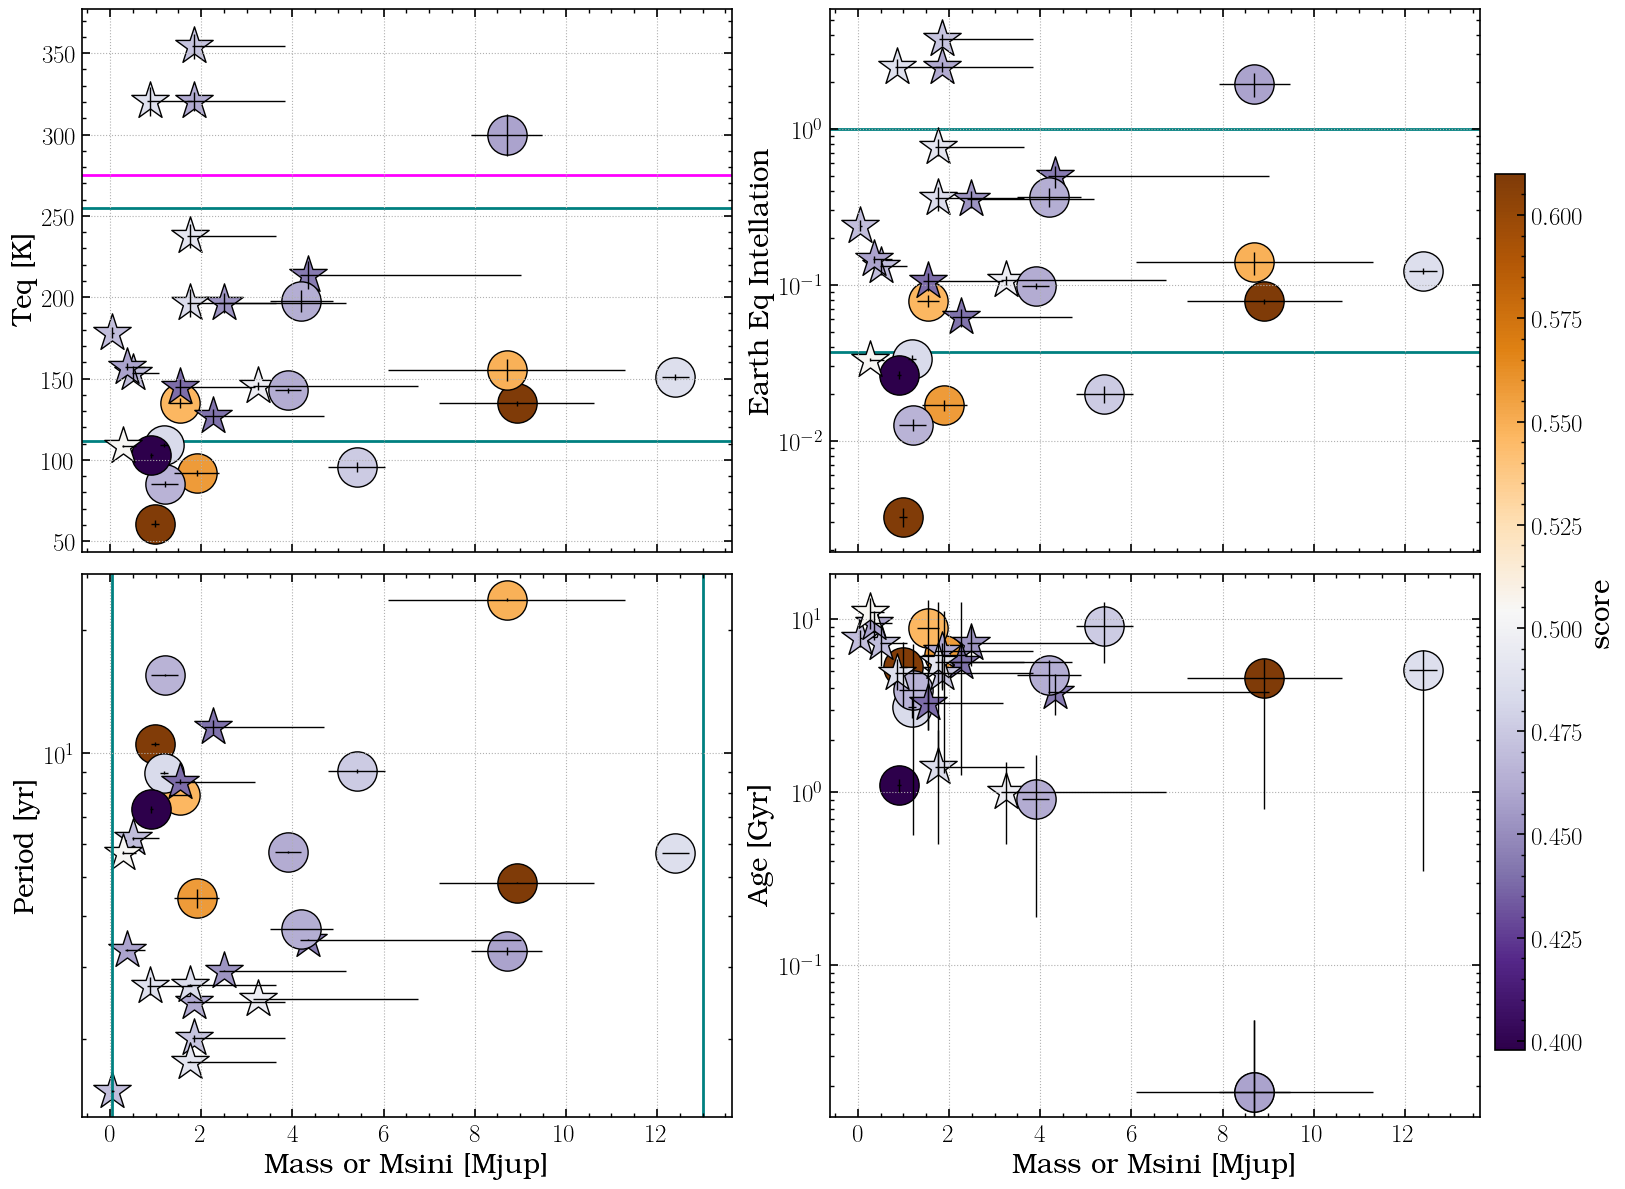

In [ ]:

from myastrotools.tools import ComputeTeq, EarthEqIntellation
fontsize = 12
markersize = 800

anDict1 = {}
for name in names:
    anDict1.update({name:[5,5]})


fig,axes = plt.subplots(nrows=2, ncols=2, figsize = (15,12), sharex=True)

ax = axes[0,0]
Teq = ComputeTeq(5780, 1*u.Rsun, 5.2*u.au, Ab = 0.3, fprime = 1/4)
ax.axhline(y=Teq, color='teal', lw=2, zorder=1)
Teq = ComputeTeq(5780, 1*u.Rsun, 1*u.au, Ab = 0.3, fprime = 1/4)
ax.axhline(y=Teq, color='teal', lw=2, zorder=1)

ax.axhline(y=275, color='magenta', lw=2, zorder=1)
for j,key in enumerate(keys):
    pl = plDict[key][[key for key in plDict[key].keys()][0]]
    if np.any(np.isnan(pl['inc'])):
        marker = '*'
    else:
        marker = 'o'
    i = np.where(targets['pl_name'] == key)[0][0]
    y = [targets.loc[i,'Teq']]
    x = [pl['Mpsini'][0]*u.Mearth.to(u.Mjup)]
    color = cmap(norm(targets.loc[i,'score']))
    if np.any(np.isnan(pl['inc'])):
        xerr = np.array([[pl['Mpsini'][1]*u.Mearth.to(u.Mjup)], [pl['Mpsini'][0]*u.Mearth.to(u.Mjup)/np.sin(np.degrees(10))]])
        yerr = np.array([[targets.loc[i,'Teq_err']],[targets.loc[i,'Teq_err']]])
    else:
        xerr = pl['Mpsini'][1]*u.Mearth.to(u.Mjup)
        yerr = targets.loc[i,'Teq_err']
    ax.scatter(x,y, s=markersize, color=color,
              edgecolors='black', marker=marker)
    ax.errorbar(x,y,
                yerr = yerr, xerr = xerr, color='black', lw=1, ls='None')
ax.grid(ls=':')


ax.set_ylabel('Teq [K]')


ax = axes[0,1]


eq = EarthEqIntellation(1, 5780, 5.2)
ax.axhline(y=eq, color='teal', lw=2, zorder=1)
ax.axhline(y=1, color='teal', lw=2, zorder=1)
for j,key in enumerate(keys):
    pl = plDict[key][[key for key in plDict[key].keys()][0]]
    if np.any(np.isnan(pl['inc'])):
        marker = '*'
    else:
        marker = 'o'
    i = np.where(targets['pl_name'] == key)[0][0]
    y = [targets.loc[i,'EarthEqInstell']]
    x = [pl['Mpsini'][0]*u.Mearth.to(u.Mjup)]
    color = cmap(norm(targets.loc[i,'score']))
    if np.any(np.isnan(pl['inc'])):
        xerr = np.array([[pl['Mpsini'][1]*u.Mearth.to(u.Mjup)], [pl['Mpsini'][0]*u.Mearth.to(u.Mjup)/np.sin(np.degrees(10))]])
    else:
        xerr = pl['Mpsini'][1]*u.Mearth.to(u.Mjup)
    yerr = [targets.loc[i,'EarthEqInstell_err']]
    ax.scatter(x,y, s=markersize, color=color,
              edgecolors='black', marker=marker)
    ax.errorbar(x,y,
                yerr = yerr, xerr = xerr, color='black', lw=1, ls='None')


ax.grid(ls=':')
ax.set_yscale('log')
ax.set_ylabel('Earth Eq Intellation')

ax = axes[1,0]


for j,key in enumerate(keys):
    pl = plDict[key][[key for key in plDict[key].keys()][0]]
    if np.any(np.isnan(pl['inc'])):
        marker = '*'
    else:
        marker = 'o'
    i = np.where(targets['pl_name'] == key)[0][0]
    y = [pl['Period'][0]*u.d.to(u.yr)]
    x = [pl['Mpsini'][0]*u.Mearth.to(u.Mjup)]
    color = cmap(norm(targets.loc[i,'score']))
    if np.any(np.isnan(pl['inc'])):
        xerr = np.array([[pl['Mpsini'][1]*u.Mearth.to(u.Mjup)], [pl['Mpsini'][0]*u.Mearth.to(u.Mjup)/np.sin(np.degrees(10))]])
    else:
        xerr = pl['Mpsini'][1]*u.Mearth.to(u.Mjup)
    yerr = [pl['Period'][1]*u.d.to(u.yr)]
    ax.scatter(x,y, s=markersize, color=color,
              edgecolors='black', marker=marker)
    ax.errorbar(x,y,
                yerr = yerr, xerr = xerr, color='black', lw=1, ls='None')

ax.axvline(1.0241e26*u.kg.to(u.Mjup), color='teal', lw=2, zorder=1)
ax.axvline(13, color='teal', lw=2, zorder=1)
ax.set_yscale('log')
ax.grid(ls=':')
ax.set_ylabel('Period [yr]')
ax.set_xlabel('Mass or Msini [Mjup]')

ax = axes[1,1]


for j,key in enumerate(keys):
    pl = plDict[key][[key for key in plDict[key].keys()][0]]
    if np.any(np.isnan(pl['inc'])):
        marker = '*'
    else:
        marker = 'o'
    i = np.where(targets['pl_name'] == key)[0][0]
    # y = [1000/pl['plx'][0]]
    y = [targets.loc[i,'age']]
    x = [pl['Mpsini'][0]*u.Mearth.to(u.Mjup)]
    color = cmap(norm(targets.loc[i,'score']))
    if np.any(np.isnan(pl['inc'])):
        xerr = np.array([[pl['Mpsini'][1]*u.Mearth.to(u.Mjup)], [pl['Mpsini'][0]*u.Mearth.to(u.Mjup)/np.sin(np.degrees(10))]])
    else:
        xerr = [pl['Mpsini'][1]*u.Mearth.to(u.Mjup)]
    yerrup = targets.loc[i,'age_err_plus']
    yerrdown = targets.loc[i,'age_err_minus']
    yerr = [[yerrup],[yerrdown]]
    ax.scatter(x,y, s=markersize, color=color,
              edgecolors='black', marker=marker)
    ax.errorbar(x,y,
                yerr = yerr, xerr = xerr, color='black', lw=1, ls='None')


ax.set_yscale('log')
ax.grid(ls=':')
ax.set_ylabel('Age [Gyr]')
ax.set_xlabel('Mass or Msini [Mjup]')

plt.tight_layout()
sm = matplotlib.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cax = fig.add_axes([1.0,0.12,0.02,0.73])
cbar = plt.colorbar(sm, cax=cax)
cbar.ax.set_ylabel('score', fontsize=20)


## System architecture plot

In [43]:
def GetHZ(StarTeff, StarRad, PlanetMass):
    ''' Get the conservative habitable zone (inner edge: runaway greenhouse, outer edge: maximum greenhouse)
    and optimistc habtiable zone (inner edge: recent Venus, outer edge: early Mars) using Eqn 4 and 5 of Kopparapu et al. 2014

    Args:
        StarTeff (flt): star effective temperature
        StarRad (flt): star radius in solar radii
        PlanetMass (flt): planet mass in Earth masses

    Returns:
        dict: inner and outer limits of consv and optimistic HZ in au
    '''
    koppDict = {
        1:{'Seff':[1.776, 1.107, 0.356, 0.320],
          'a':[2.136e-4, 1.332e-4, 6.17e-5, 5.547e-5],
           'b':[2.533e-8, 1.58e-8, 1.698e-9, 1.526e-9],
           'c':[-1.332e-11, -8.308e-12, -3.198e-12,-2.874e-12],
           'd':[-3.097e-15, -1.931e-15, -5.575e-16, -5.011e-16]
          },
        5:{'Seff':[1.776, 1.188, 0.356, 0.320],
          'a':[2.136e-4, 1.433e-4, 6.17e-5, 5.547e-5],
           'b':[2.533e-8, 1.707e-8, 1.698e-9, 1.526e-9],
           'c':[-1.332e-11, -8.968e-12, -3.198e-12,-2.874e-12],
           'd':[-3.097e-15, -2.084e-15, -5.575e-16, -5.011e-16]
          },
        0.1:{'Seff':[1.776, 0.99, 0.356, 0.320],
            'a':[2.136e-4, 1.209e-4, 6.17e-5, 5.547e-5],
             'b':[2.533e-8, 1.404e-8, 1.698e-9, 1.526e-9],
             'c':[-1.332e-11, -7.418e-12, -3.198e-12,-2.874e-12],
             'd':[-3.097e-15, -1.713e-15, -5.575e-16, -5.011e-16]
            }
    }
    keys = np.array([key for key in koppDict.keys()])
    diff = np.abs(PlanetMass - keys)
    key = keys[np.where(diff == min(diff))[0]]
    sDict = koppDict[key[0]]
    T_star = StarTeff - 5780

    StarLum = (StarRad)**2 * (StarTeff/5780)**4

    outDict = {}
    keys = ['OptInner','ConsvInner','ConsvOuter','OptOuter']
    for i in range(4):
        Seff = sDict['Seff'][i] + sDict['a'][i]*T_star + sDict['b'][i]*T_star**2 + sDict['c'][i]*T_star**3 + sDict['d'][i]*T_star**4
        d = (StarLum / Seff)**(0.5)
        outDict.update({keys[i]:d})
    return outDict

In [44]:
hzkeys = ['OptInner','ConsvInner','ConsvOuter','OptOuter']
for key in hzkeys:
    targets[key] = np.nan


In [45]:

for j,key in enumerate(keys):
    pl = plDict[key][[key for key in plDict[key].keys()][0]]
    i = np.where(targets['pl_name'] == key)[0][0]
    mass = pl['Mpsini'][0]
    Rstar = pl['Rstar'][0]
    Teff = pl['StarTeff'][0]
    hz = GetHZ(Teff, Rstar, mass)
    for k,hzkey in enumerate(hzkeys):
        targets.loc[i,hzkey] = hz[hzkey]

In [46]:
from orbitdict import *
targets['sma'] = np.nan
targets['sma_err'] = np.nan
targets['Mp'] = np.nan
targets['Mp_err'] = np.nan
targets['Mp_is_Mpsini'] = np.nan
for j,key in enumerate(keys):
    pl = plDict[key][[key for key in plDict[key].keys()][0]]
    i = np.where(targets['pl_name'] == key)[0][0]
    targets.loc[i,'sma'] = pl['sma'][0]
    targets.loc[i,'sma_err'] = pl['sma'][1]
    targets.loc[i,'Mp'] = pl['Mpsini'][0]
    targets.loc[i,'Mp_err'] = pl['Mpsini'][1]
    if pl['Mp_is_Mpsini']:
        targets.loc[i,'Mp_is_Mpsini'] = 1
    else:
        targets.loc[i,'Mp_is_Mpsini'] = 0

In [48]:
sortsma = np.array(np.argsort(targets['sma']))
targets_sort = targets.loc[sortsma]
targets_sort = targets_sort.reset_index(drop=True)

starnames_sort = np.array(starnames)[sortsma]
planets_letter = [name[-1:] for name in targets_sort['pl_name']]

In [49]:
### Add extra companions in systems:

moreplDict = {}
for starname in starnames_sort:
    moreplDict.update({starname:{}})
moreplDict.update({'$\\beta$ Pic': {'d':{'sma':26.0, 'mass':763}}})
moreplDict.update({'47 UMa': {'d':{'sma':11.6, 'mass':521}}})
moreplDict.update({'HD 160691': {'d':{'sma':0.095, 'mass':10.5},
                                'e':{'sma':0.96, 'mass':156},
                                }})
moreplDict.update({'$\\upsilon$ And': 
                                {'c':{'sma':0.849, 'mass':653},
                                'b':{'sma':0.0607, 'mass':227},
                                 'B':{'sma':750 ,'mass':0.19*u.Msun.to(u.Mearth)}}
                                })
moreplDict.update({'$\\pi$ Men': 
                                {'c':{'sma':0.0705, 'mass':4.2},
                                'd':{'sma':0.506, 'mass':16}
                                }})
moreplDict.update({'HD 114783': {'b':{'sma':1.2, 'mass':331}}})
moreplDict.update({'HD 190360': 
                                {'c':{'sma':0.1298, 'mass':26.6},
                                 'd':{'sma':0.3886, 'mass':11.9},
                                 'B':{'sma': 179*(1000/63) ,'mass':0.2076*u.Msun.to(u.Mearth)}
                                }})
moreplDict.update({'14 Her': {'c':{'sma':20, 'mass':2511}}})
moreplDict.update({'$\\gamma$ Cep': {'B':{'sma':20, 'mass':0.4*u.Msun.to(u.Mearth)}}})
moreplDict.update({'HD 219134':
                              {'b':{'sma':0.0387, 'mass':4.74},
                               'c':{'sma':0.0653, 'mass':4.36},
                               'd':{'sma':0.237, 'mass':16.17} # also f and g but they're controversial
                              }
                  })
moreplDict.update({'HD 192310':
                              {'b':{'sma':0.32, 'mass':13.64},
                              }
                  })
moreplDict.update({'HD 164922':
                              {'c':{'sma':0.341, 'mass':13},
                               'd':{'sma':0.103, 'mass':4},
                               'e':{'sma':0.2292, 'mass':10.5}
                              }
                  })
# moreplDict.update({'GJ 687 c':
#                               {'b':{'sma':0.163, 'mass':17.2},
#                               }
                  # })
moreplDict.update({'HD 128311':
                              {'b':{'sma':1.08, 'mass':636},
                              }
                  })
moreplDict.update({'$\\psi^1$ Dra B':
                                {'B':{'sma':704.28, 'mass':1.38*u.Msun.to(u.Mjup)}}})

In [50]:
starnames_unique = starnames_sort[[0,2,4,5,7,8,9,10,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26]]
starnames_unique

array(['HD 192310', 'HD 128311', '$\\gamma$ Cep', 'HD 10647', '7 CMa',
       'HD 164922', 'HD 216437', '$\\upsilon$ And', 'HD 219134', '14 Her',
       '$\\pi$ Men', 'HD 70642', '47 UMa', '$\\epsilon$ Eri', 'GJ 832',
       'HD 190360', 'HD 87883', 'HD 154345', '$\\psi^1$ Dra B',
       'HD 114783', 'HD 160691', 'HD 100508', '$\\beta$ Pic'],
      dtype='<U14')

In [52]:

plotDict = {}
ind = []
for i,name in enumerate(starnames_unique):
    plotDict.update({name:i})


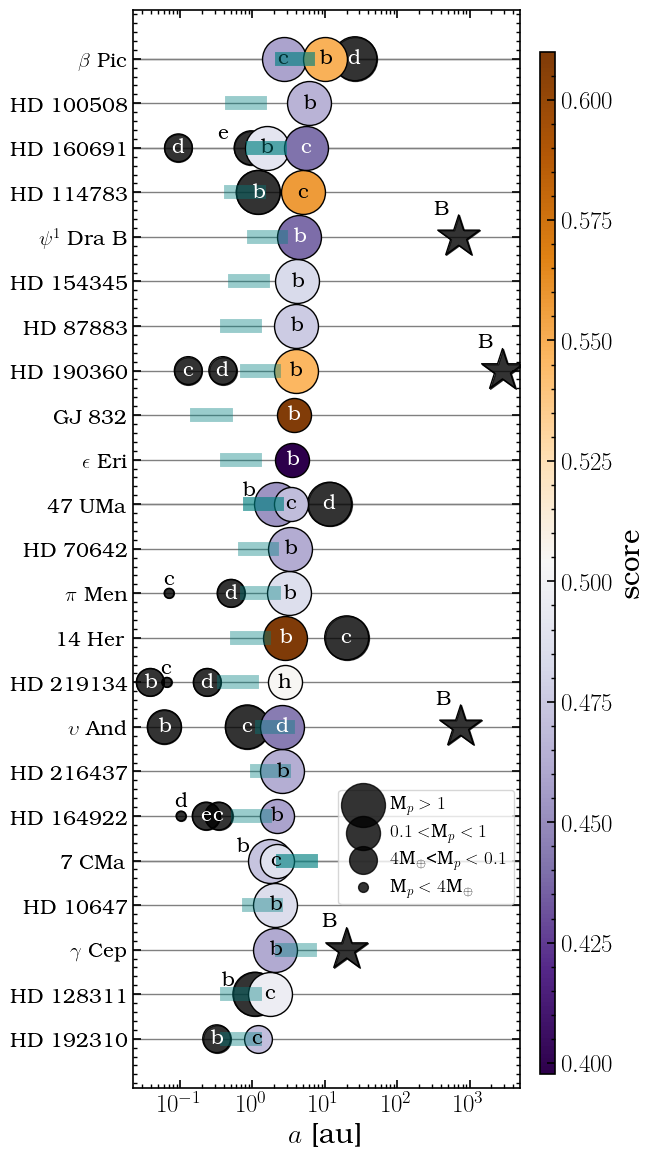

In [54]:
ys = np.arange(0,len(np.unique(starnames_unique)),1)
Mp = targets_sort.loc[i,'Mp']*u.Mearth.to(u.Mjup) 

fig,ax = plt.subplots(figsize=(5,14))

import matplotlib
cmap = matplotlib.colormaps.get_cmap('PuOr_r')
norm = mpl.colors.Normalize(vmin=min(targets['score']), vmax=max(targets['score']))
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)



sizemultiple = 0.4
for i in range(len(targets)):
    planet = targets_sort.loc[i,'pl_name']
    planetletter = planet[-2:]
    star = starnames_sort[i]
    y = ys[plotDict[star]]
    x = targets_sort.loc[i,'sma']
    color = cmap(norm(targets_sort.loc[i,'score']))
    ax.plot([targets_sort.loc[i,'OptInner'], targets_sort.loc[i,'OptOuter']],[y,y],
            lw=10, color='teal', zorder=10, alpha = 0.4
             )
    ax.axhline(y, lw=1, color='grey', zorder=0)
    Mp = targets_sort.loc[i,'Mp']*u.Mearth.to(u.Mjup) 
    if Mp > 1 and Mp < 13:
        size = 1000
        marker = 'o'
    elif Mp > 0.1 and Mp < 1:
        size = 600
        marker = 'o'
    elif Mp < 0.1:
        size = 400
        marker = 'o'
    else:
        size = 200
        marker = '*'
    ax.scatter(x, y, s=size, color=color, zorder=9, marker=marker,
              edgecolor='black')
    if targets_sort.loc[i,'score'] < 0.45 or targets_sort.loc[i,'score'] > 0.6 :
        textcolor='white'
    else:
        textcolor='black'
        
    if planet == '47 UMa b':
        textcolor='black'
        offsets = [-20,10]
    elif planet == '7 CMa b':
        textcolor='black'
        offsets = [-20,10]
    else:
        offsets = [0,0]
    ax.annotate(planetletter, xy=(x, y), xytext=(offsets[0],offsets[1]), textcoords='offset points', zorder=10,
               fontsize=15, ha='center', va='center', color=textcolor)


for key in moreplDict.keys():
    y = ys[plotDict[key]]
    morekeys = [k for k in moreplDict[key].keys()]
    if len(morekeys) > 0:
        for k in morekeys:
            x = moreplDict[key][k]['sma']
            Mp = moreplDict[key][k]['mass']*u.Mearth.to(u.Mjup)
            if k == 'B':
                size = 1000
                marker = '*'
                offsets = [-12,20]
                textcolor='black'
            elif Mp > 1 and Mp < 13:
                size = 1000
                marker = 'o'
                offsets = [0,0]
                textcolor='white'
            elif Mp > 0.1 and Mp < 1:
                size = 600
                marker = 'o'
                offsets = [0,0]
                textcolor='white'
            elif Mp < 0.13 and Mp > 0.014:
                size = 400
                marker = 'o'
                offsets = [0,0]
                textcolor='white'
            elif Mp < 0.014:
                size = 50
                marker = 'o'
                offsets = [0,10]
                textcolor='black'
            
            if key == 'HD 160691' and k == 'e':
                textcolor='black'
                offsets = [-20,10]
            if key == 'HD 128311' and k == 'b':
                textcolor='black'
                offsets = [-20,10]
                
            if key == '$\\beta$ Pic' and k == 'd':
                a1 = ax.scatter(x,y, s=size, color='black', marker=marker, alpha=0.8, label='M$_p>1$')
                ax.scatter(x,y, s=size, facecolors='none', edgecolor='black', marker=marker)
                ax.annotate(k, xy=(x,y), xytext=(offsets[0],offsets[1]), textcoords='offset points', zorder=10,
                   fontsize=15, ha='center', va='center', color=textcolor)
            elif key == 'HD 160691' and k == 'e':
                a2 = ax.scatter(x,y, s=size, color='black', marker=marker, alpha=0.8, label='$0.1<$M$_p<1$')
                ax.scatter(x,y, s=size, facecolors='none', edgecolor='black', marker=marker)
                ax.annotate(k, xy=(x,y), xytext=(offsets[0],offsets[1]), textcoords='offset points', zorder=10,
                   fontsize=15, ha='center', va='center', color=textcolor)
            elif key == '$\\pi$ Men' and k == 'd':
                a3 = ax.scatter(x,y, s=size, color='black', marker=marker, alpha=0.8, label='$4$M$_\\oplus$<M$_p<0.1$')
                ax.scatter(x,y, s=size, facecolors='none', edgecolor='black', marker=marker)
                ax.annotate(k, xy=(x,y), xytext=(offsets[0],offsets[1]), textcoords='offset points', zorder=10,
                   fontsize=15, ha='center', va='center', color=textcolor)
            elif key == '$\\pi$ Men' and k == 'c':
                a4 = ax.scatter(x,y, s=size, color='black', marker=marker, alpha=0.8, label='M$_p<4$M$_\\oplus$')
                ax.scatter(x,y, s=size, facecolors='none', edgecolor='black', marker=marker)
                ax.annotate(k, xy=(x,y), xytext=(offsets[0],offsets[1]), textcoords='offset points', zorder=10,
                   fontsize=15, ha='center', va='center', color=textcolor)
            else:
                ax.scatter(x,y, s=size, color='black', marker=marker, alpha=0.8)
                ax.scatter(x,y, s=size, facecolors='none', edgecolor='black', marker=marker)
                ax.annotate(k, xy=(x,y), xytext=(offsets[0],offsets[1]), textcoords='offset points', zorder=10,
                   fontsize=15, ha='center', va='center', color=textcolor)



yticks = np.arange(0,len(starnames_unique),1)
ax.set_yticks(yticks,starnames_unique, fontsize=15)
ax.set_xscale('log')
ax.set_xlabel('$a$ [au]')
#ax.set_xlim(1,12)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])
cax = fig.add_axes([0.94,0.12,0.03,0.73])
cbar = plt.colorbar(sm, cax=cax)
cbar.ax.set_ylabel('score', fontsize=20)
cbar.ax.set_zorder(1)

handles, labels = ax.get_legend_handles_labels()
hh = []
ll = []
for i in [1,0,3,2]:
    hh.append(handles[i])
    ll.append(labels[i])
legend = ax.legend(handles=hh, labels=ll, loc =(0.53,0.17), fontsize=13)
legend.set_zorder(10) 

#plt.savefig('system_architecture.png', bbox_inches='tight')

# Accessible to METIS

In [56]:
L = pd.read_csv('METIS-cvc-Lband.csv', skiprows=2, names=['mag2-sep','mag2-cont', 'mag8-sep', 'mag8-cont'])
N = pd.read_csv('METIS-cvc-Nband.csv', skiprows=2, names=['mag1-sep','mag1-cont', 'mag4-sep', 'mag4-cont'])

### Flame skimmer evolution tables

This section uses tools and models provided by Flame Skimmer models https://zenodo.org/records/20030439

In [99]:
from evolution_lookup_onefile import *

In [101]:
targets['Teff'] = np.nan
targets['Lum'] = np.nan
targets['radius_FlameSkimmer'] = np.nan
for i in range(len(targets)):
    Mp = targets.loc[i,'Mp']
    if targets.loc[i,'Mp_is_Mpsini'] == 1:
        Mp = Mp/(np.sin(np.radians(60)))
    print(Mp*u.Mearth.to(u.Mjup),targets.loc[i,'age'])
    try:
        result = evolution_lookup(
            source="flame_skimmer",
            path="/Users/lapearce/Dropbox/astro_packages/Others-Packages/Sonora-FlameSkimmer/flameskimmer_evolution_tables/deq/mh+0.0_co1.0.txt",
            mass = Mp*u.Mearth.to(u.Mjup),
            age = targets.loc[i,'age']
        )
        targets.loc[i,'Teff'] = result['teff']
        targets.loc[i,'Lum'] = result['luminosity_lsun']
        targets.loc[i,'radius_FlameSkimmer'] = result['radius']
    except KeyError:
        pass

8.919907538709916 4.6
0.99 5.27
1.9 6.2
1.5385660622325041 8.85
8.7 0.0185
1.1859858721838856 3.1
5.409000000000001 9.1
12.400000000000002 5.1
1.2 3.902
8.699662908124486 0.0185
0.91 1.1
2.1361959960016157 6.6
5.006403797996038 3.8
2.877513741641095 7.3
0.5958254778036939 7.3
2.611932617813867 5.666
0.05195324696033624 7.81
3.7529863014005134 1.0
2.0200003713249615 1.4
2.1361959960016157 4.9
0.42143892639153874 9.58
4.2 4.75
1.004589468389949 4.9
0.3197122889866845 11.0
3.8999999999999995 0.92
2.0200003713249615 5.666
1.7666918237202551 3.3


In [102]:
ind = np.where(targets['pl_name'] == 'bet Pic b')[0][0]

targets.loc[ind,'Teff'] = 1640
targets['Lum'] = -3.71
targets['radius_FlameSkimmer'] = 1.68

ind = np.where(targets['pl_name'] == 'bet Pic c')[0][0]

targets.loc[ind,'Teff'] = 1640
targets['Lum'] = -3.71
targets['radius_FlameSkimmer'] = 1.68

In [104]:
flux_table = pd.read_csv(
    '/Users/lapearce/Dropbox/astro_packages/Others-Packages/Sonora-FlameSkimmer/flame_skimmer_publication/deq/ground/mh+0.0_co1.0_flux.txt',
                         sep='\\s+')
[cc for cc in flux_table.columns]

['Teff',
 'log(g)',
 'log(kzz)',
 'Mass/Mjup',
 'Radius/Rjup',
 'Age/Gyr',
 'log(L/Lsun)',
 '2MASS.H',
 '2MASS.J',
 '2MASS.Ks',
 'Keck_NIRC2.H',
 'Keck_NIRC2.J',
 'Keck_NIRC2.K',
 'Keck_NIRC2.Kp',
 'Keck_NIRC2.Ks',
 'Keck_NIRC2.Lp',
 'Keck_NIRC2.Ms',
 'LSST.i',
 'LSST.r',
 'LSST.y',
 'LSST.z',
 'MKO_NSFCam.H',
 'MKO_NSFCam.J',
 'MKO_NSFCam.K',
 'MKO_NSFCam.Kp',
 'MKO_NSFCam.Ks',
 'MKO_NSFCam.Lp',
 'MKO_NSFCam.Mp',
 'SDSS.iprime',
 'SDSS.rprime',
 'SDSS.zprime',
 'UKIRT_WFCAM.H',
 'UKIRT_WFCAM.J',
 'UKIRT_WFCAM.K',
 'UKIRT_WFCAM.Y',
 'UKIRT_WFCAM.Z',
 'VLT_NACO.H',
 'VLT_NACO.J',
 'VLT_NACO.Ks',
 'VLT_NACO.Lp',
 'VLT_NACO.Mp',
 'VLT_NACO.NB_4.05',
 'VLT_SPHERE.IRDIS_H',
 'VLT_SPHERE.IRDIS_H2',
 'VLT_SPHERE.IRDIS_H3',
 'VLT_SPHERE.IRDIS_J',
 'VLT_SPHERE.IRDIS_J2',
 'VLT_SPHERE.IRDIS_J3',
 'VLT_SPHERE.IRDIS_K1',
 'VLT_SPHERE.IRDIS_K2',
 'VLT_SPHERE.IRDIS_Ks',
 'VLT_SPHERE.IRDIS_Y',
 'VLT_VISIR.B87',
 'VLT_VISIR.PAH2',
 'VLT_VISIR.SiC']

In [106]:
# diff = np.abs(mass - flux_table['Mass/Mjup'])
# ind = np.where(diff == min(diff))
# Lp = np.array(flux_table.loc[ind,'VLT_NACO.Lp'])[2]
# Lp
targets['VLT/NACO_Lp_Flux'] = np.nan

for i in range(len(targets)):
    Mp = targets.loc[i,'Mp']
    if targets.loc[i,'Mp_is_Mpsini'] == 1:
        Mp = Mp/(np.sin(np.radians(60)))
    mass = Mp*u.Mearth.to(u.Mjup)
    age = targets.loc[i,'age']
    try:
        diff = np.abs(mass - flux_table['Mass/Mjup'])
        ind = np.where(diff == min(diff))
        rad = targets.loc[i,'radius_FlameSkimmer']*u.Rjup
        dist = targets.loc[i,'sy_dist']*u.pc
        omega = ((rad.to(u.km) / (dist.to(u.km))).decompose())**2
        targets.loc[i,'VLT/NACO_Lp_Flux'] = np.array(flux_table.loc[ind,'VLT_NACO.Lp'])[2] * omega
        
    except:
        print(i)

In [107]:
i = 0
rad = targets.loc[i,'radius_FlameSkimmer']*u.Rjup
dist = targets.loc[i,'sy_dist']*u.pc
targets.loc[i,'sy_dist']*u.pc,((rad / dist).decompose())**2

(<Quantity 17.9323 pc>, <Quantity 4.71151279e-20>)

In [108]:
import pysynphot as S

In [109]:
i = 0
mh = targets.loc[i,'st_met']
teff = targets.loc[i,'StarTeff']
rad = targets.loc[i,'StarRad']
logg = targets.loc[i,'st_logg']
sp = S.Icat('phoenix', teff, mh, logg)

(1e-10, 183.66746131294752)

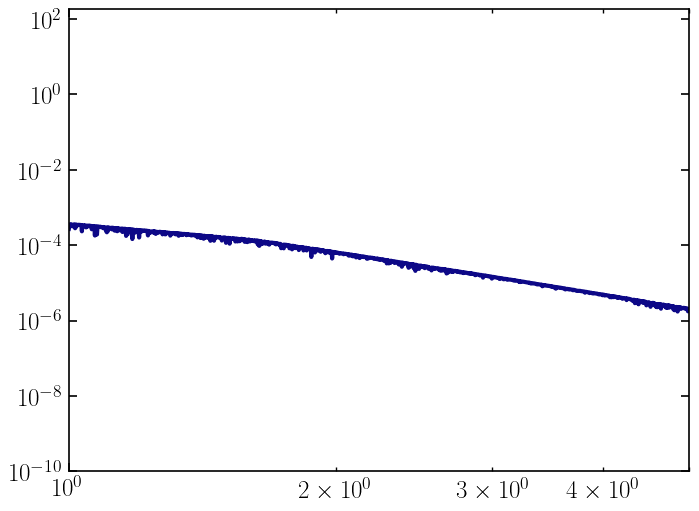

In [110]:
rad = targets.loc[i,'StarRad']*u.Rsun
dist = targets.loc[i,'sy_dist']*u.pc
omega = ((rad/dist).decompose())**2
flux = sp.flux*(u.erg/u.s/(u.cm**2)/u.AA).to(u.erg/u.s/(u.cm**2)/u.cm) * omega
wave = sp.wave*u.AA.to(u.um)
plt.plot(wave, flux)
plt.gca().set_yscale('log')
plt.gca().set_xscale('log')
plt.xlim(1,5)
plt.ylim(bottom=1e-10)

In [111]:
vega = S.Vega
vega87 = vega.sample(8.7*u.um.to(u.AA))*(u.erg/u.s/(u.cm**2)/u.AA).to(u.erg/u.s/(u.cm**2)/u.cm)
vega38 = vega.sample(3.8*u.um.to(u.AA))*(u.erg/u.s/(u.cm**2)/u.AA).to(u.erg/u.s/(u.cm**2)/u.cm)

In [113]:

## Star:

from myastrotools.tools import FluxLambda0

targets['8.7um_star_flux'] = np.nan
targets['3.8um_star_flux'] = np.nan
targets['8.7um_star_mag'] = np.nan
targets['3.8um_star_mag'] = np.nan
for i in range(len(targets)):
    mh = targets.loc[i,'st_met']
    teff = targets.loc[i,'StarTeff']
    rad = targets.loc[i,'StarRad']*u.Rsun
    logg = targets.loc[i,'st_logg']
    dist = targets.loc[i,'sy_dist']*u.pc
    sp = S.Icat('phoenix', teff, mh, logg)
    omega = (rad.to(u.km) / (dist.to(u.km))).decompose()**2
    flux = sp.flux*(u.erg/u.s/(u.cm**2)/u.AA).to(u.erg/u.s/(u.cm**2)/u.cm) * omega
    wave = sp.wave*u.AA.to(u.um)
    targets.loc[i,'3.8um_star_flux'] = FluxLambda0(wave,flux,3.8)
    targets.loc[i,'8.7um_star_flux'] = FluxLambda0(wave,flux,8.7)
    targets.loc[i,'3.8um_star_mag'] = -2.5*np.log10(targets.loc[i,'3.8um_star_flux']/vega38)
    targets.loc[i,'8.7um_star_mag'] = -2.5*np.log10(targets.loc[i,'8.7um_star_flux']/vega87)

In [115]:
import xarray
path = '/Users/lapearce/Dropbox/astro_packages/Others-Packages/Sonora-FlameSkimmer/flame_skimmer_R30000/'
teff = 300
ds = xarray.open_dataset(path+'teff_{}/mh_+1.0/co_1.0/spectra_logkzz_7_teff_{}_grav_31_mh_+1.0_co_1.0_R30000.nc'.format(teff,teff))
from ReflectX import MeanRegrid, CreateGrid
r100 = CreateGrid(min(ds['wavelength']), max(ds['wavelength']), 100)

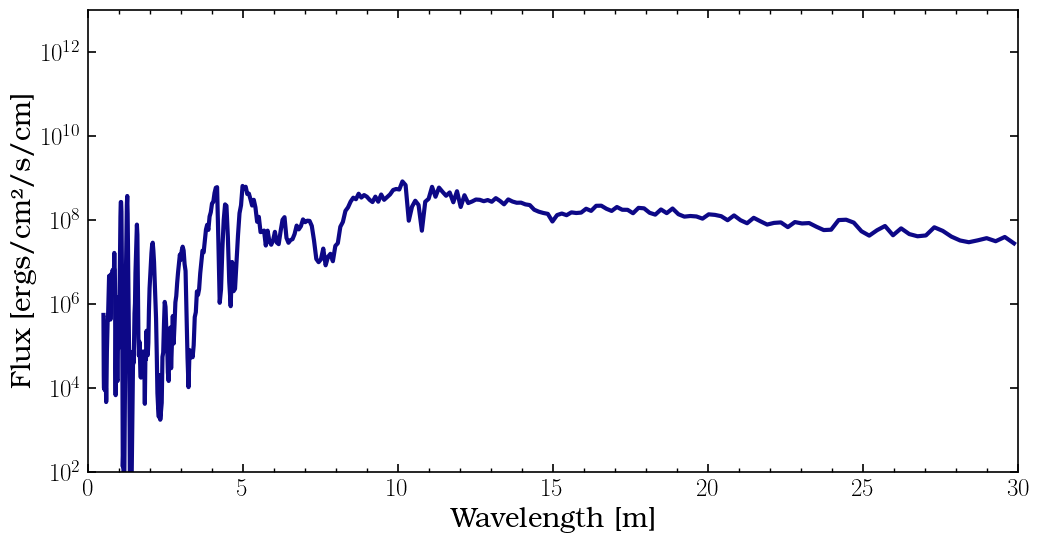

In [116]:
w,f = MeanRegrid(ds['wavelength'], ds['flux_emission'], newx = r100)
fig, ax = plt.subplots(figsize=(12, 6))


plt.semilogy(w,f)
plt.xlabel('Wavelength [m]')
plt.ylabel('Flux [ergs/cm²/s/cm]')
plt.xlim(0,30)
plt.ylim(1e2, 1e13)
plt.show()

In [117]:
### Planets:

Teffs =  [50, 100, 150, 200, 250, 300, 350, 400, 450]
gravs = [1,1.7,3.1,5.6,10,17,31,56,100,178,316,562,1000,1780,3160]

targets['3.8um_FlameSkimmer_flux'] = np.nan
targets['8.7um_FlameSkimmer_flux'] = np.nan
targets['8.7um_flux_contrast'] = np.nan
targets['3.8um_flux_contrast'] = np.nan
path = '/Users/lapearce/Dropbox/astro_packages/Others-Packages/Sonora-FlameSkimmer/flame_skimmer_R30000/'
for i in range(len(targets)):
    realteff = targets.loc[i,'Teff']
    teffdiff = np.abs(realteff - Teffs)

    Mp = targets.loc[i,'Mp']
    if targets.loc[i,'Mp_is_Mpsini'] == 1:
        Mp = Mp/(np.sin(np.radians(60)))
    mass = Mp*u.Mearth.to(u.Mjup)
    rad = targets.loc[i,'radius_FlameSkimmer']
    g = (c.G * (mass*u.Mjup)/((rad*u.Rjup)**2)).cgs.value
    gdiff = np.abs((g/100) - gravs)
    try:
        ind = np.where(teffdiff == min(teffdiff))[0][0]
        teff = Teffs[ind]
        ind = np.where(gdiff == min(gdiff))[0][0]
        grav = gravs[ind]
        
        ds = xarray.open_dataset(path+\
                                 'teff_{}/mh_+1.0/co_1.0/spectra_logkzz_7_teff_{}_grav_{}_mh_+1.0_co_1.0_R30000.nc'\
                                 .format(teff,teff,grav) )
        w,f = MeanRegrid(ds['wavelength'], ds['flux_emission'], newx = r100)
        rad = targets.loc[i,'radius_FlameSkimmer']*u.Rjup
        dist = targets.loc[i,'sy_dist']*u.pc
        omega = ((rad.to(u.km) / (dist.to(u.km))).decompose())**2
        targets.loc[i,'3.8um_FlameSkimmer_flux'] = FluxLambda0(w,f,3.8)*omega
        targets.loc[i,'8.7um_FlameSkimmer_flux'] = FluxLambda0(w,f,8.7)*omega
        targets.loc[i,'8.7um_flux_contrast'] = targets.loc[i,'8.7um_FlameSkimmer_flux'] / targets.loc[i,'8.7um_star_flux']
        targets.loc[i,'3.8um_flux_contrast'] = targets.loc[i,'3.8um_FlameSkimmer_flux'] / targets.loc[i,'3.8um_star_flux']
        print(i)
    except:
        pass
#

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
24
25
26


In [118]:
i = np.where(targets['pl_name'] == '14 Her b')[0][0]
targets.loc[i,'3.8um_FlameSkimmer_flux']*(u.erg/u.s/(u.cm**2)/u.cm).to(u.W/(u.m**2)/u.um)
# this looks about right given 14 Her c's flux in the JWST paper

3.4087620629611986e-19

In [119]:
i = np.where(targets['pl_name'] == 'bet Pic b')[0][0]
realteff = targets.loc[i,'Teff']
realteff

1640.0

In [120]:
#### Diamondback for beta Pic:

i = np.where(targets['pl_name'] == 'bet Pic b')[0][0]
realteff = targets.loc[i,'Teff']

Mp = targets.loc[i,'Mp']
if targets.loc[i,'Mp_is_Mpsini'] == 1:
    Mp = Mp/(np.sin(np.radians(60)))
mass = Mp*u.Mearth.to(u.Mjup)
rad = targets.loc[i,'radius_FlameSkimmer']
rad = 1.4
g = (c.G * (mass*u.Mjup)/((rad*u.Rjup)**2)).cgs.value
teff = 1700
logg = 4.0
grav = (10**logg)/100
fseds = [1,2,3,4,8]
mh = '0.0'
co = 1.0

fsed = fseds[0]

path = '/Users/lapearce/Dropbox/astro_packages/Others-Packages/Sonora-Diamondback/spectra/'
spec = pd.read_table(path+'t{}g{}f{}_m{}_co{}.spec'.format(teff,int(grav),fsed,mh,co),
                    names=['wavelength (micron)','flux (W/m2/m)'], sep='\\s+', skiprows=3)
# plt.plot(spec['wavelength (micron)'], spec['flux (W/m2/m)'])
# plt.gca().set_yscale('log')
# plt.gca().set_xscale('log')


w,f = MeanRegrid(spec['wavelength (micron)'], spec['flux (W/m2/m)'], newx = r100)
rad = targets.loc[i,'radius_FlameSkimmer']*u.Rjup
dist = targets.loc[i,'sy_dist']*u.pc
omega = ((rad.to(u.km) / (dist.to(u.km))).decompose())**2
flux = FluxLambda0(w,f,3.8)*omega
flux = flux*(u.W/(u.m**2)/u.m).to(u.W/(u.m**2)/u.um)
print(flux)

targets['3.8um_FlameSkimmer_flux_Wm2um'] = np.nan
targets.loc[i,'3.8um_FlameSkimmer_flux_Wm2um'] = flux

targets['8.7um_FlameSkimmer_flux_Wm2um'] = np.nan
targets.loc[i,'8.7um_FlameSkimmer_flux_Wm2um'] = flux
flux = FluxLambda0(w,f,8.7)*omega
flux = flux*(u.W/(u.m**2)/u.m).to(u.W/(u.m**2)/u.um)
print(flux)

targets.loc[i,'3.8um_FlameSkimmer_flux'] = targets.loc[i,'3.8um_FlameSkimmer_flux_Wm2um'] *(u.W/(u.m**2)/u.um).to(u.erg/u.s/(u.cm**2)/u.cm)
targets.loc[i,'8.7um_FlameSkimmer_flux'] = targets.loc[i,'8.7um_FlameSkimmer_flux_Wm2um'] *(u.W/(u.m**2)/u.um).to(u.erg/u.s/(u.cm**2)/u.cm)
targets.loc[i,'8.7um_flux_contrast'] = targets.loc[i,'8.7um_FlameSkimmer_flux'] / targets.loc[i,'8.7um_star_flux']
targets.loc[i,'3.8um_flux_contrast'] = targets.loc[i,'3.8um_FlameSkimmer_flux'] / targets.loc[i,'3.8um_star_flux']


2.1894261066533527e-15
1.4422335222444743e-16


In [121]:
i = np.where(targets['pl_name'] == 'bet Pic c')[0][0]
realteff = targets.loc[i,'Teff']

Mp = targets.loc[i,'Mp']
if targets.loc[i,'Mp_is_Mpsini'] == 1:
    Mp = Mp/(np.sin(np.radians(60)))
mass = Mp*u.Mearth.to(u.Mjup)
rad = targets.loc[i,'radius_FlameSkimmer']
rad = 1.4
g = (c.G * (mass*u.Mjup)/((rad*u.Rjup)**2)).cgs.value
teff = 1700
logg = 4.0
grav = (10**logg)/100
fseds = [1,2,3,4,8]
mh = '0.0'
co = 1.0

fsed = fseds[0]

path = '/Users/lapearce/Dropbox/astro_packages/Others-Packages/Sonora-Diamondback/spectra/'
spec = pd.read_table(path+'t{}g{}f{}_m{}_co{}.spec'.format(teff,int(grav),fsed,mh,co),
                    names=['wavelength (micron)','flux (W/m2/m)'], sep='\\s+', skiprows=3)
# plt.plot(spec['wavelength (micron)'], spec['flux (W/m2/m)'])
# plt.gca().set_yscale('log')
# plt.gca().set_xscale('log')


w,f = MeanRegrid(spec['wavelength (micron)'], spec['flux (W/m2/m)'], newx = r100)
rad = targets.loc[i,'radius_FlameSkimmer']*u.Rjup
dist = targets.loc[i,'sy_dist']*u.pc
omega = ((rad.to(u.km) / (dist.to(u.km))).decompose())**2
flux = FluxLambda0(w,f,3.8)*omega
flux = flux*(u.W/(u.m**2)/u.m).to(u.W/(u.m**2)/u.um)
print(flux)

targets['3.8um_FlameSkimmer_flux_Wm2um'] = np.nan
targets.loc[i,'3.8um_FlameSkimmer_flux_Wm2um'] = flux

targets['8.7um_FlameSkimmer_flux_Wm2um'] = np.nan
targets.loc[i,'8.7um_FlameSkimmer_flux_Wm2um'] = flux
flux = FluxLambda0(w,f,8.7)*omega
flux = flux*(u.W/(u.m**2)/u.m).to(u.W/(u.m**2)/u.um)
print(flux)

targets.loc[i,'3.8um_FlameSkimmer_flux'] = targets.loc[i,'3.8um_FlameSkimmer_flux_Wm2um'] *(u.W/(u.m**2)/u.um).to(u.erg/u.s/(u.cm**2)/u.cm)
targets.loc[i,'8.7um_FlameSkimmer_flux'] = targets.loc[i,'8.7um_FlameSkimmer_flux_Wm2um'] *(u.W/(u.m**2)/u.um).to(u.erg/u.s/(u.cm**2)/u.cm)
targets.loc[i,'8.7um_flux_contrast'] = targets.loc[i,'8.7um_FlameSkimmer_flux'] / targets.loc[i,'8.7um_star_flux']
targets.loc[i,'3.8um_flux_contrast'] = targets.loc[i,'3.8um_FlameSkimmer_flux'] / targets.loc[i,'3.8um_star_flux']

2.1894261066533527e-15
1.4422335222444743e-16


In [ ]:
### Thermal contribution from star:

Teffs =  [50, 100, 150, 200, 250, 300, 350, 400, 450]
gravs = [1,1.7,3.1,5.6,10,17,31,56,100,178,316,562,1000,1780,3160]

Jup_Ab_38 = 0.05

targets['3.8um_star_thermal_flux'] = np.nan
targets['8.7um_star_thermal_flux'] = np.nan
targets['3.8um_total_thermal_flux'] = np.nan
targets['8.7um_total_thermal_flux'] = np.nan
targets['8.7um_flux_contrast'] = np.nan
targets['3.8um_flux_contrast'] = np.nan
# This part depends on downloading Flame Skimmer models
path = 'Sonora-FlameSkimmer/flame_skimmer_R30000/'
for i in range(len(targets)):
    star = targets.loc[i,'3.8um_star_flux']
    rad = targets.loc[i,'radius_FlameSkimmer']*u.Rjup.to(u.km)
    sma = targets.loc[i,'pl_orbsmax']*u.au.to(u.km)
    targets.loc[i,'3.8um_star_thermal_flux'] =  star * (1-Jup_Ab_38)/4 * ((rad/sma)**2)
    star = targets.loc[i,'8.7um_star_flux']
    targets.loc[i,'8.7um_star_thermal_flux'] =  star * (1-Jup_Ab_38)/4 * ((rad/sma)**2)
    targets.loc[i,'3.8um_total_thermal_flux'] = targets.loc[i,'3.8um_star_thermal_flux'] + targets.loc[i,'3.8um_FlameSkimmer_flux']
    targets.loc[i,'8.7um_total_thermal_flux'] = targets.loc[i,'8.7um_star_thermal_flux'] + targets.loc[i,'8.7um_FlameSkimmer_flux']
    targets.loc[i,'8.7um_flux_contrast'] = targets.loc[i,'8.7um_total_thermal_flux'] / targets.loc[i,'8.7um_star_flux']
    targets.loc[i,'3.8um_flux_contrast'] = targets.loc[i,'3.8um_total_thermal_flux'] / targets.loc[i,'3.8um_star_flux']
    
#

Text(0.5, 0, 'Separation [arcsec]')

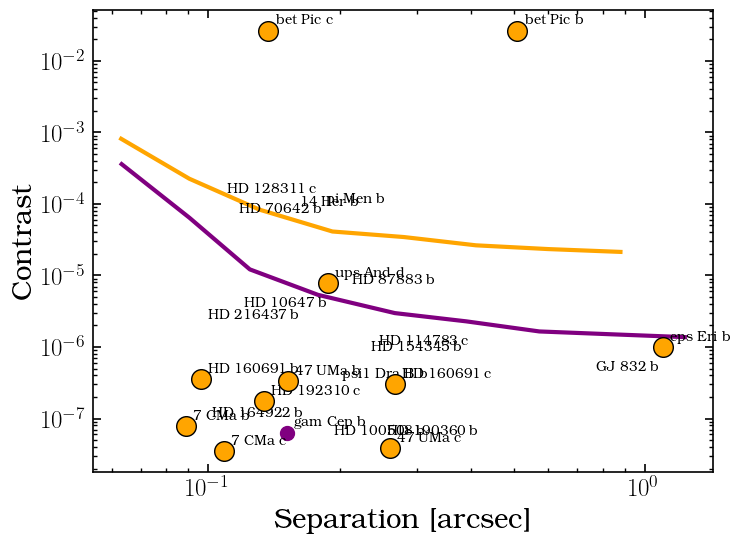

In [124]:
fig,ax = plt.subplots()
ax.plot(N['mag1-sep'],N['mag1-cont'],color='purple')
ax.plot(N['mag4-sep'],N['mag4-cont'],color='orange')
sma_as = targets['pl_orbsmax'] / targets['sy_dist']
for i in range(len(targets)):
    if targets.loc[i,'8.7um_star_mag'] <1.5:
        ax.scatter(sma_as[i],targets.loc[i,'8.7um_flux_contrast'], s=100, color='purple')
    elif targets.loc[i,'8.7um_star_mag'] <4:
        ax.scatter(sma_as[i],targets.loc[i,'8.7um_flux_contrast'], s=200, color='orange', edgecolor='black', zorder=10)
    ax.annotate(targets.loc[i,'pl_name'], xy =(sma_as[i],targets.loc[i,'8.7um_flux_contrast']), xytext=(5,5), textcoords='offset points' )
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_ylabel('Contrast')
ax.set_xlabel('Separation [arcsec]')

Text(0.5, 0, 'Separation [arcsec]')

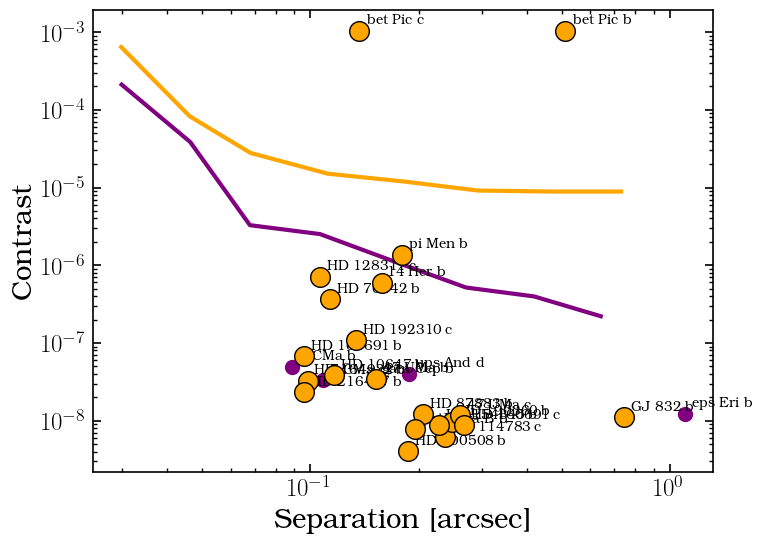

In [125]:
fig,ax = plt.subplots()
ax.plot(L['mag2-sep'],L['mag2-cont'], color='purple')
ax.plot(L['mag8-sep'],L['mag8-cont'], color='orange')
sma_as = targets['pl_orbsmax'] / targets['sy_dist']
for i in range(len(targets)):
    if targets.loc[i,'3.8um_star_mag'] <3:
        ax.scatter(sma_as[i],targets.loc[i,'3.8um_flux_contrast'], s=100, color='purple')
    elif targets.loc[i,'3.8um_star_mag'] <8:
        ax.scatter(sma_as[i],targets.loc[i,'3.8um_flux_contrast'], s=200, color='orange', edgecolor='black', zorder=10)
    ax.annotate(targets.loc[i,'pl_name'], xy =(sma_as[i],targets.loc[i,'3.8um_flux_contrast']), xytext=(5,5), textcoords='offset points' )

ax.set_yscale('log')
ax.set_xscale('log')
ax.set_ylabel('Contrast')
ax.set_xlabel('Separation [arcsec]')

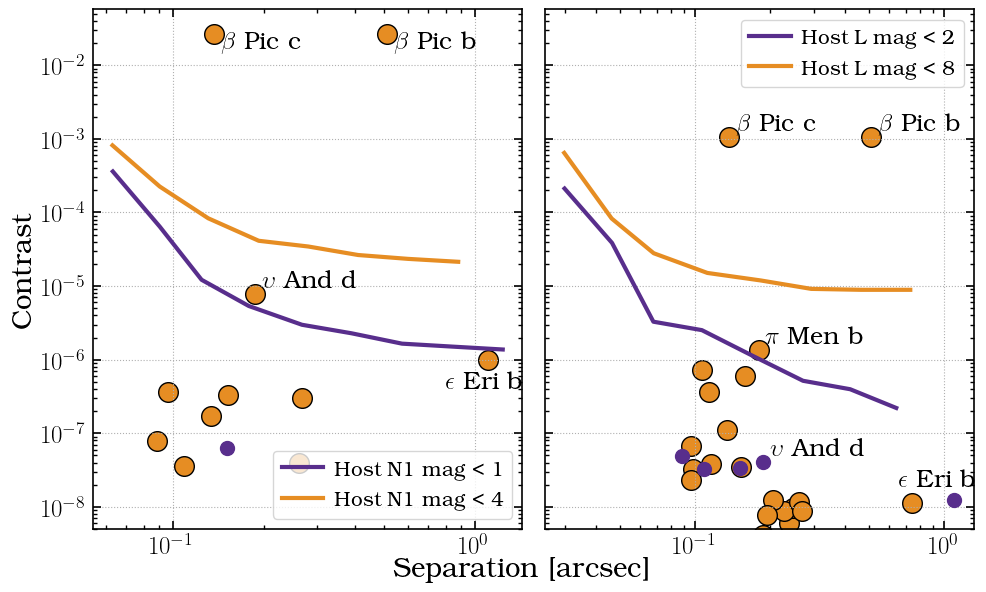

In [152]:

cmap = matplotlib.colormaps.get_cmap('PuOr_r')
colors = cmap(np.linspace(0,1,10))

fig,axes = plt.subplots(nrows=1, ncols=2, sharey=True, figsize=(10,6))
ax = axes[0]
ax.plot(N['mag1-sep'],N['mag1-cont'],color=colors[1], label='Host N1 mag < 1 ')
ax.plot(N['mag4-sep'],N['mag4-cont'],color=colors[7], label='Host N1 mag < 4')
sma_as = targets['pl_orbsmax'] / targets['sy_dist']
for i in range(len(targets)):
    if targets.loc[i,'8.7um_star_mag'] <1.5:
        ax.scatter(sma_as[i],targets.loc[i,'8.7um_flux_contrast'], s=100, color=colors[1], zorder=10)
    elif targets.loc[i,'8.7um_star_mag'] <4:
        ax.scatter(sma_as[i],targets.loc[i,'8.7um_flux_contrast'], s=200, color=colors[7], edgecolor='black')
    if targets.loc[i,'pl_name'] == 'bet Pic b':
        ax.annotate('$\\beta$ Pic b', xy =(sma_as[i],targets.loc[i,'8.7um_flux_contrast']), xytext=(5,-10), textcoords='offset points',
                   fontsize=18)
    if targets.loc[i,'pl_name'] == 'bet Pic c':
        ax.annotate('$\\beta$ Pic c', xy =(sma_as[i],targets.loc[i,'8.7um_flux_contrast']), xytext=(5,-10), textcoords='offset points',
                   fontsize=18)
    if targets.loc[i,'pl_name'] == 'eps Eri b':
        ax.annotate('$\\epsilon$ Eri b', xy =(sma_as[i],targets.loc[i,'8.7um_flux_contrast']), xytext=(-30,-20), textcoords='offset points',
                   fontsize=18)
    if targets.loc[i,'pl_name'] == 'ups And d':
        ax.annotate('$\\upsilon$ And d', xy =(sma_as[i],targets.loc[i,'8.7um_flux_contrast']), xytext=(5,5), textcoords='offset points',
                   fontsize=18)

ax.set_yscale('log')
ax.set_xscale('log')
ax.set_ylabel('Contrast')
ax.set_xlabel('Separation [arcsec]')
ax.xaxis.set_label_coords(1, -0.05)
ax.legend(fontsize=15, loc='lower right')
ax.grid(ls=':')

ax = axes[1]
ax.plot(L['mag2-sep'],L['mag2-cont'], color=colors[1], label='Host L mag < 2 ')
ax.plot(L['mag8-sep'],L['mag8-cont'], color=colors[7], label='Host L mag < 8')
sma_as = targets['pl_orbsmax'] / targets['sy_dist']
for i in range(len(targets)):
    if targets.loc[i,'3.8um_star_mag'] <3:
        ax.scatter(sma_as[i],targets.loc[i,'3.8um_flux_contrast'], s=100, color=colors[1], zorder=10)
    elif targets.loc[i,'3.8um_star_mag'] <8:
        ax.scatter(sma_as[i],targets.loc[i,'3.8um_flux_contrast'], s=200, color=colors[7], edgecolor='black')
    if targets.loc[i,'pl_name'] == 'bet Pic b':
        ax.annotate('$\\beta$ Pic b', xy =(sma_as[i],targets.loc[i,'3.8um_flux_contrast']), xytext=(5,5), textcoords='offset points',
                   fontsize=18)
    if targets.loc[i,'pl_name'] == 'bet Pic c':
        ax.annotate('$\\beta$ Pic c', xy =(sma_as[i],targets.loc[i,'3.8um_flux_contrast']), xytext=(5,5), textcoords='offset points',
                   fontsize=18)
    if targets.loc[i,'pl_name'] == 'eps Eri b':
        ax.annotate('$\\epsilon$ Eri b', xy =(sma_as[i],targets.loc[i,'3.8um_flux_contrast']), xytext=(-40,10), textcoords='offset points',
                   fontsize=18)
    if targets.loc[i,'pl_name'] == 'ups And d':
        ax.annotate('$\\upsilon$ And d', xy =(sma_as[i],targets.loc[i,'3.8um_flux_contrast']), xytext=(5,5), textcoords='offset points',
                   fontsize=18)
    if targets.loc[i,'pl_name'] == 'pi Men b':
        ax.annotate('$\\pi$ Men b', xy =(sma_as[i],targets.loc[i,'3.8um_flux_contrast']), xytext=(5,5), textcoords='offset points',
                   fontsize=18)
ax.legend(fontsize=15)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_ylim(bottom=5e-9)
ax.grid(ls=':')
plt.tight_layout()
plt.savefig('METIS-contrast.png', bbox_inches='tight')

## Is reflected light significant at these wavelengths?

In [268]:
from picaso import justdoit as jdi

In [272]:
opacity = jdi.opannection(
    filename_db = '/Users/lapearce/Dropbox/astro_packages/Others-Packages/picaso/reference/opacities/opacities_0.3_15_R15000.db',
                          wave_range=[3,10],verbose=True)
start_case = jdi.inputs()
#phase angle
start_case.phase_angle(0) #radians
#define gravity
start_case.gravity(radius = 1, radius_unit=u.Rjup, mass=1, mass_unit=u.Mjup) #any astropy units available
#define star
start_case.star(opacity, 5870,0,4.0, semi_major=5, semi_major_unit=u.au)

verbose=True; Molecule set= ['C2H2' 'CH4' 'CO' 'CO2' 'H2O' 'H2S' 'K' 'Na' 'OCS' 'SO2']


In [273]:
comp_file = jdi.pd.read_csv(jdi.jupiter_pt(), sep=r'\s+')


In [274]:
start_case.atmosphere(filename=jdi.jupiter_pt(), sep=r'\s+')
import virga.justdoit as vdi
clouds = vdi.recommend_gas(comp_file['pressure'], comp_file['temperature'], 
                  1, 2.2, plot=False, returnplot=False)
kzz = 1e7
fsed = 8
# add kzz:
comp_file['kz'] = [float(kzz)]*comp_file.shape[0]
start_case.atmosphere(df=comp_file)
meiff_directory = '/Users/lapearce/Dropbox/astro_packages/Others-Packages/virga/virga/reference/RefIndexFiles'
if 'SiO2' in clouds:
    clouds.remove('SiO2')
if 'tholin' in clouds:
    clouds.remove('tholin')
clouds_added = start_case.virga(clouds, meiff_directory, 
                                        fsed= float(fsed), mh=1,
                                        mmw = float(2.2), verbose=False)

Not doing sublayer as cloud deck at the bottom of pressure grid


Text(0, 0.5, 'Ag')

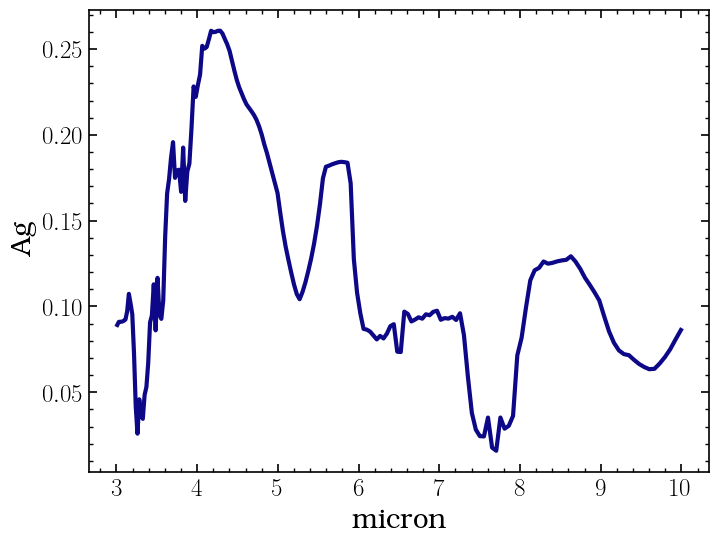

In [283]:
df = start_case.spectrum(opacity,calculation='reflected')
wno, alb, fpfs = df['wavenumber'] , df['albedo'] , df['fpfs_reflected']
wno, alb = jdi.mean_regrid(wno, alb , R=150)
plt.plot(1e4/wno, alb)
plt.xlabel('micron')
plt.ylabel('Ag')

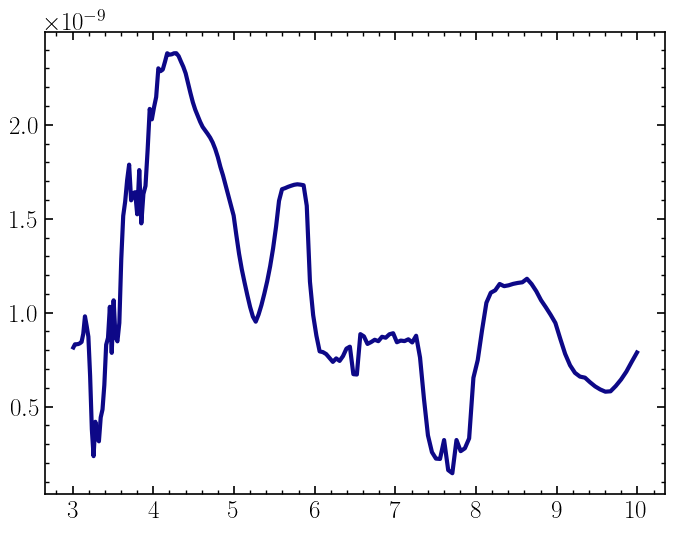

In [276]:
df = start_case.spectrum(opacity,calculation='reflected')
wno, fpfs = jdi.mean_regrid(df['wavenumber'], df['fpfs_reflected'] , R=150)
#wno, fpfs = df['wavenumber'], df['fpfs_reflected']
plt.plot(1e4/wno, fpfs)

In [279]:
Jup_refl_Ag_87 = FluxLambda0(1e4/wno, alb, 8.7)
Jup_refl_Ag_38 = FluxLambda0(1e4/wno, alb, 3.8)
Jup_refl_Ag_87,Jup_refl_Ag_38

(array(0.12529859), array(0.16740059))

In [281]:
### Refl light at N band::

targets['8.7um_refl_flux_contrast'] = np.nan
targets['8.7um_flux_contrast'] = np.nan
targets['3.8um_refl_flux_contrast'] = np.nan
targets['3.8um_flux_contrast'] = np.nan

for i in range(len(targets)):
    star = targets.loc[i,'8.7um_star_flux']
    rad = targets.loc[i,'radius_FlameSkimmer']*u.Rjup.to(u.km)
    sma = targets.loc[i,'pl_orbsmax']*u.au.to(u.km)
    targets.loc[i,'8.7um_refl_flux_contrast'] =  star * Jup_refl_Ag_87 * ((rad/sma)**2)
    targets.loc[i,'8.7um_flux_contrast'] = targets.loc[i,'8.7um_total_thermal_flux'] / targets.loc[i,'8.7um_star_flux']  + targets.loc[i,'8.7um_refl_flux_contrast']

    star = targets.loc[i,'3.8um_star_flux']
    targets.loc[i,'3.8um_refl_flux_contrast'] =  star * Jup_refl_Ag_38 * ((rad/sma)**2)
    targets.loc[i,'3.8um_flux_contrast'] = targets.loc[i,'3.8um_total_thermal_flux'] / targets.loc[i,'3.8um_star_flux']  + targets.loc[i,'3.8um_refl_flux_contrast']


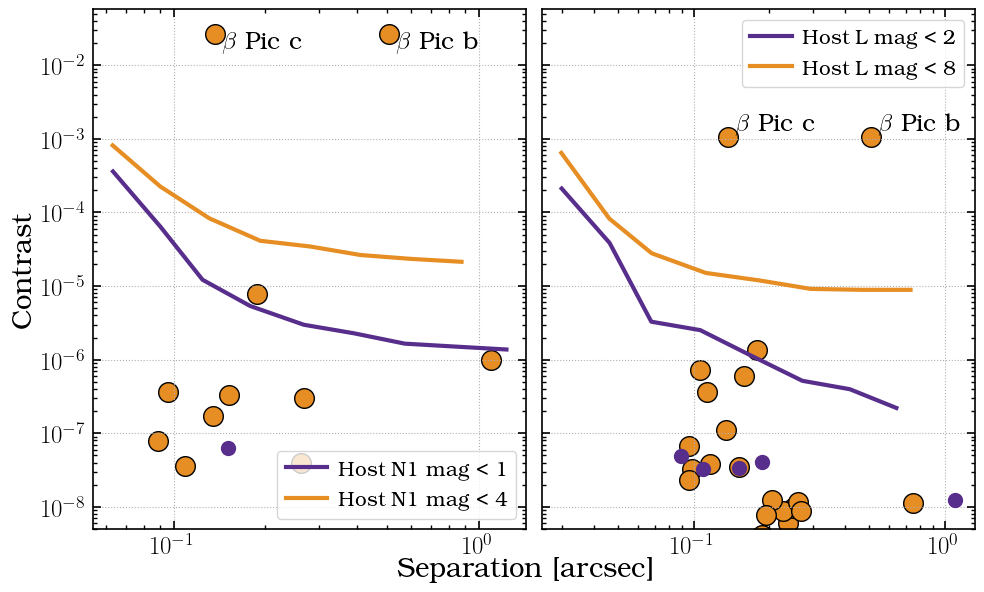

In [282]:

cmap = matplotlib.colormaps.get_cmap('PuOr_r')
colors = cmap(np.linspace(0,1,10))

fig,axes = plt.subplots(nrows=1, ncols=2, sharey=True, figsize=(10,6))
ax = axes[0]
ax.plot(N['mag1-sep'],N['mag1-cont'],color=colors[1], label='Host N1 mag < 1 ')
ax.plot(N['mag4-sep'],N['mag4-cont'],color=colors[7], label='Host N1 mag < 4')
sma_as = targets['pl_orbsmax'] / targets['sy_dist']
for i in range(len(targets)):
    if targets.loc[i,'8.7um_star_mag'] <1.5:
        ax.scatter(sma_as[i],targets.loc[i,'8.7um_flux_contrast'], s=100, color=colors[1], zorder=10)
    elif targets.loc[i,'8.7um_star_mag'] <4:
        ax.scatter(sma_as[i],targets.loc[i,'8.7um_flux_contrast'], s=200, color=colors[7], edgecolor='black')
    if targets.loc[i,'pl_name'] == 'bet Pic b':
        ax.annotate('$\\beta$ Pic b', xy =(sma_as[i],targets.loc[i,'8.7um_flux_contrast']), xytext=(5,-10), textcoords='offset points',
                   fontsize=18)
    if targets.loc[i,'pl_name'] == 'bet Pic c':
        ax.annotate('$\\beta$ Pic c', xy =(sma_as[i],targets.loc[i,'8.7um_flux_contrast']), xytext=(5,-10), textcoords='offset points',
                   fontsize=18)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_ylabel('Contrast')
ax.set_xlabel('Separation [arcsec]')
ax.xaxis.set_label_coords(1, -0.05)
ax.legend(fontsize=15, loc='lower right')
ax.grid(ls=':')

ax = axes[1]
ax.plot(L['mag2-sep'],L['mag2-cont'], color=colors[1], label='Host L mag < 2 ')
ax.plot(L['mag8-sep'],L['mag8-cont'], color=colors[7], label='Host L mag < 8')
sma_as = targets['pl_orbsmax'] / targets['sy_dist']
for i in range(len(targets)):
    if targets.loc[i,'3.8um_star_mag'] <3:
        ax.scatter(sma_as[i],targets.loc[i,'3.8um_flux_contrast'], s=100, color=colors[1], zorder=10)
    elif targets.loc[i,'3.8um_star_mag'] <8:
        ax.scatter(sma_as[i],targets.loc[i,'3.8um_flux_contrast'], s=200, color=colors[7], edgecolor='black')
    if targets.loc[i,'pl_name'] == 'bet Pic b':
        ax.annotate('$\\beta$ Pic b', xy =(sma_as[i],targets.loc[i,'3.8um_flux_contrast']), xytext=(5,5), textcoords='offset points',
                   fontsize=18)
    if targets.loc[i,'pl_name'] == 'bet Pic c':
        ax.annotate('$\\beta$ Pic c', xy =(sma_as[i],targets.loc[i,'3.8um_flux_contrast']), xytext=(5,5), textcoords='offset points',
                   fontsize=18)
ax.legend(fontsize=15)
ax.set_yscale('log')
ax.set_xscale('log')
ax.set_ylim(bottom=5e-9)
ax.grid(ls=':')
plt.tight_layout()
plt.savefig('METIS-contrast.png', bbox_inches='tight')

In [159]:
targets.to_csv('targets.csv', index=False)

# Gaia DR4 and DR5 Lazuli predictions:

From Lammers and Winn 2026:
Catalog from https://zenodo.org/records/17568375

https://ui.adsabs.harvard.edu/abs/2026AJ....171...18L/abstract

In [59]:
dr4 = pd.read_csv('DR4_mock_exoplanet_catalog.csv')
dr5 = pd.read_csv('DR5_mock_exoplanet_catalog.csv')

### Converting the L&W catalog to projected sep vs reflected light contrast

This part uses the projecc package

In [60]:
from projecc import KeplerianToCartesian, KeplersConstant, DanbySolve, EccentricityAnomaly, update_progress

def ComputeFluxRatio(Rp, sep_in_orbit_plane, alpha, Ag = 0.5):
    ''' For a single planet compute planet/star flux ratio using Cahoy 2010 eqn 1
    and https://ui.adsabs.harvard.edu/abs/2017ApJ...844...89C/abstract

    Args:
        Rp (astropy units object): planet radius
        sep (astropy units object): planet-star separation in the plane of the orbit (true separation)
        alpha (flt): phase angle in degrees
        Ag (flt): geometric albedo

    Returns:
        flt: planet-star contrast
    '''
    alpha = np.radians(alpha)
    angleterm = (np.sin(alpha) + (np.pi - alpha)*np.cos(alpha)) / np.pi
    Rp = Rp.to(u.km)
    sep_in_orbit_plane = sep_in_orbit_plane.to(u.km)
    C = Ag * ((Rp / sep_in_orbit_plane)**2) * angleterm
    return C


def PlanetMass2Radius(M):
    ''' Emperical mass-radius relation for planets and brown dwarfs by Jared
        taken from 
        https://jaredmales.github.io/mxlib-doc/group__planets.html#ga4b350ecfdeaca1bedb897db770b09789
    '''
    try:
        M = M.to(u.Mearth)
        M = M.value
    except:
        pass

    if M < 4.1:
        R = M**(1/3)

    if M >= 4.1 and M < 15.84:
        R = 0.62 * M**(0.67)

    if M >= 15.84 and M < 3591.1:
        coeff = [14.0211, -44.8414, 53.6554, -25.3289, 5.4920, -0.4586]
        power = [0, 1, 2, 3, 4, 5]
        R = 0
        for i in range(6):
            R += coeff[i] * (np.log10(M)**power[i])

    if M >= 3591.1:
        R = 32.03 * M**(-1/8)

    return R


def GetPhaseAngle(MeanAnom, ecc, inc, argp):
    ''' Function for returning observed phase angle given orbital elements
    Args:
        MeanAnom (flt): Mean anomly in radians, where MeanAnom = orbit fraction*2pi, or M=2pi * time/Period
        ecc (flt): eccentricity, defined on [0,1)
        inc (flt): inclination in degrees, where inc = 90 is edge on, inc = 0 or 180 is face on orbit
        argp (flt): argument of periastron in degrees, defined on [0,360)

    Returns:
        flt: phase angle in degrees
    Written by Logan Pearce, 2023
    '''
    import numpy as np
    inc = np.radians(inc)
    argp = np.radians(argp)
    EccAnom = DanbySolve(EccentricityAnomaly, MeanAnom, ecc, 0.001, maxnum=50)
    TrueAnom = 2*np.arctan( np.sqrt( (1+ecc)/(1-ecc) ) * np.tan(EccAnom/2) )
    Alpha = np.arccos( np.sin(inc) * np.sin(TrueAnom + argp) )
    return np.degrees(Alpha)

def GetOrbitPlaneOfSky(sma,ecc,inc,argp,lon,meananom,kep):
    ''' For a value fo sma, ecc, inc, argp, lan, and mass, compute the position in the sky plane for one or
    an array of mean anomaly values past periastron.

    args:
        sma [astropy unit object]: semi-major axis in au
        ecc [flt]: eccentricity
        inc [flt]: inclination in degrees
        argp [flt]: argument of periastron in degrees
        lon [flt]: longitude of nodes in degrees
        meananom [flt or arr]: a single value or array of values for the mean anomaly in radians at which 
            to compute positions
        kep [astropy unit object]: value of Kepler's constant for the system

    returns:
        flt or arr: X value of position, where +x corresponds to +Declination
        flt or arr: Y value, where +Y corresponds to +Right Ascension
        flt or arr: Z value, where +Z corresponds to towards the observer
    '''
    pos, vel, acc = KeplerianToCartesian(sma,ecc,inc,argp,lon,meananom,kep)
    return pos[0].value, pos[1].value, pos[2].value

def GetOrbitPlaneOfOrbit(sma,ecc,meananom,kep):
    ''' For a value fo sma, ecc, and mass, compute the position in the orbit plane for one or
    an array of mean anomaly values past periastron.

    args:
        sma [astropy unit object]: semi-major axis in au
        ecc [flt]: eccentricity
        meananom [flt or arr]: a single value or array of values for the mean anomaly in radians at which 
            to compute positions
        kep [astropy unit object]: value of Kepler's constant for the system

    returns:
        flt or arr: x value of position, where +x corresponds to semi-major axis towards periastron
        flt or arr: y value, where +y corresponds to semi-minor axis counterclockwise perpendiculat to +x
        flt or arr: z value, where +z corresponds to angular momentum vector for right handed system
    '''
    import numpy as np
    import astropy.units as u
    E = DanbySolve(EccentricityAnomaly, meananom, ecc, 0.001)
    return (sma*(np.cos(E) - ecc)).value, (sma*np.sqrt(1-ecc**2)*np.sin(E)).value, 0

def ComputeThings(M1, M2, sma, ecc, inc, argp, lon, Rp, Ag=0.3):
    # compute kepler's constant:
    kep = KeplersConstant(M1,M2)
    # empt arrays to store things:
    xs = []
    ys = []
    zs = []
    truexs = []
    trueys = []
    truezs = []
    alphas = []
    n=500
    # array of mean anomalies for each point on the orbit:
    meananom = np.linspace(0,2*np.pi,n)
    # for each point:
    for j in range(len(meananom)):
        # get x,y,z postion in plane of orbit and plane of sky
        pos_planeofsky = GetOrbitPlaneOfSky(sma,ecc,inc,argp,lon,meananom[j],kep)
        pos_planeoforbit = GetOrbitPlaneOfOrbit(sma,ecc,meananom[j],kep)

        xs.append(pos_planeofsky[0])
        ys.append(pos_planeofsky[1])
        zs.append(pos_planeofsky[2])
        truexs.append(pos_planeoforbit[0])
        trueys.append(pos_planeoforbit[1])
        truezs.append(pos_planeoforbit[2])
        # compute phase at that point:
        alpha = GetPhaseAngle(meananom[j], ecc, inc, argp)
        alphas.append(alpha)

    # turn into arrays for mathing:
    xs = np.array(xs)
    ys = np.array(ys)
    zs = np.array(zs)
    truexs = np.array(truexs)
    trueys = np.array(trueys)
    truezs = np.array(truezs)
    alphas = np.array(alphas)

    # get separation in plane of orbit and sky at each orbit point:
    sep_planeoforbit = np.sqrt(truexs**2 + trueys**2)
    sep_planeofsky = np.sqrt(xs**2 + ys**2)
    # get contrasts at each orbit point:
    contrasts = np.array([ComputeFluxRatio(Rp, sep_planeoforbit[i]*u.au, alphas[i], Ag = Ag) for i in range(len(alphas))])

    return xs, ys, zs, truexs, trueys, truezs, sep_planeoforbit, sep_planeofsky, alphas, contrasts

#### This cell takes a long time to run!!!!

In [ ]:
from projecc import update_progress

# compute sma:
smadr4 = (dr4['Stellar mass [M_\\odot]'] * (dr4['True period [days]']*u.d.to(u.yr))**2)**(1/3)
# estimate radius from M-R
rad = np.array([PlanetMass2Radius(M*u.Mjup) for M in dr4['True planet mass [M_J]']])

# containers for results
maxprojseps = []
phases = []
conts = []
seps_planeofsky = []
seps_planeoforbit = []
allconts = []
allphases = []
Gmag = []

for i in range(len(dr4)):
    # get the stuff:
    M1 = dr4.loc[i,'Stellar mass [M_\\odot]']*u.Msun
    M2 = dr4.loc[i,'True planet mass [M_J]']*u.Mjup
    sma = smadr4[i]*u.au
    ecc = dr4.loc[i,'True eccentricity']
    inc = dr4.loc[i,'True inclination [deg]'] # deg
    argp = dr4.loc[i,'True omega [deg]'] # deg
    lon = dr4.loc[i,'True Omega [deg]'] # deg
    Rp = rad[i]*u.Rearth
    # compute the things
    xs, ys, zs, truexs, trueys, truezs, sep_planeoforbit, sep_planeofsky, alphas, contrasts = ComputeThings(M1,M2,sma,ecc,inc,argp,lon,Rp,Ag=0.3)
    # find the max projected separation and it's index:
    maxprojsep = np.max(sep_planeofsky)
    maxprojsepind = np.where(sep_planeofsky == maxprojsep)[0]
    # record the results:
    maxprojseps.append(sep_planeofsky[maxprojsepind])
    phases.append(alphas[maxprojsepind])
    conts.append(contrasts[maxprojsepind])
    seps_planeofsky.append(sep_planeofsky)
    seps_planeoforbit.append(sep_planeoforbit)
    allconts.append(contrasts)
    allphases.append(alphas)
    Gmag.append(dr4.loc[i,'G-band mag'])
    update_progress(i,len(dr4))

phases = np.array([phases[i][0] for i in range(len(phases))])
conts = np.array([conts[i][0] for i in range(len(conts))])
maxprojseps = np.array([maxprojseps[i][0] for i in range(len(maxprojseps))])
maxprojseps_mas = (maxprojseps/dr4['True distance [pc]'])*1000
pickle.dump([phases, conts, maxprojseps, maxprojseps_mas, rad, Gmag], open('dr4allthethings.pkl','wb'))

#### This cell takes a LOOOOONG time to run!!!!

In [ ]:

smadr5 = (dr5['Stellar mass [M_\\odot]'] * (dr5['True period [days]']*u.d.to(u.yr))**2)**(1/3)


rad5 = np.array([PlanetMass2Radius(M*u.Mjup) for M in dr5['True planet mass [M_J]']])

maxprojseps = np.array([])
phases = np.array([])
conts = np.array([])
seps_planeofsky = []
seps_planeoforbit = []
allconts = []
allphases = []
Gmag = []

for i in range(len(dr5)):
    # get the stuff:
    M1 = dr5.loc[i,'Stellar mass [M_\\odot]']*u.Msun
    M2 = dr5.loc[i,'True planet mass [M_J]']*u.Mjup
    sma = smadr5[i]*u.au
    ecc = dr5.loc[i,'True eccentricity']
    inc = dr5.loc[i,'True inclination [deg]'] # deg
    argp = dr5.loc[i,'True omega [deg]'] # deg
    lon = dr5.loc[i,'True Omega [deg]'] # deg
    Rp = rad5[i]*u.Rearth
    # compute the things
    xs, ys, zs, truexs, trueys, truezs, sep_planeoforbit, sep_planeofsky, alphas, contrasts = ComputeThings(M1,M2,sma,ecc,inc,argp,lon,Rp,Ag=0.3)
    # find the max projected separation and it's index:
    maxprojsep = np.max(sep_planeofsky)
    maxprojsepind = np.where(sep_planeofsky == maxprojsep)[0]
    # record the results:
    maxprojseps = np.append(maxprojseps,sep_planeofsky[maxprojsepind])
    phases=np.append(phases,alphas[maxprojsepind])
    conts=np.append(conts,contrasts[maxprojsepind])
    Gmag.append(dr5.loc[i,'G-band mag'])
    # seps_planeofsky=np.append(sep_planeofsky)
    # seps_planeoforbit.append(sep_planeoforbit)
    # allconts.append(contrasts)
    # allphases.append(alphas)
    update_progress(i,len(dr5))


maxprojseps_mas = (maxprojseps/dr5['True distance [pc]'])*1000
pickle.dump([phases, conts, maxprojseps, maxprojseps_mas, rad5, Gmag], open('dr5allthethings.pkl','wb'))

#### Here are the pickle files so you don't have to run those cells!

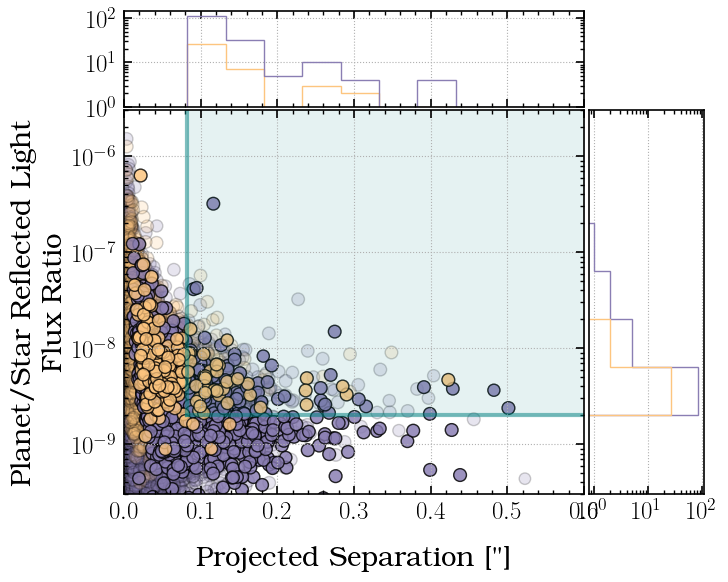

In [58]:
phases4, conts4, maxprojseps4, maxprojseps_mas4, rad4, Gmag4 = pickle.load(open('dr4allthethings.pkl','rb'))
phases5, conts5, maxprojseps5, maxprojseps_mas5, rad5, Gmag5 = pickle.load(open('dr5allthethings.pkl','rb'))


#rad5 = np.array([PlanetMass2Radius(M*u.Mjup) for M in dr5['True planet mass [M_J]']])
import matplotlib
cmap = matplotlib.colormaps.get_cmap('PuOr')
colors = cmap(np.linspace(0,1,10))

lod = 0.2063 * 0.4/3
IWA = 3 * lod
lod = 0.2063 * 0.63/3
OWA = 20 * lod
cmin = 3e-5
cgoal = 2e-9

import matplotlib as mpl
from myastrotools.tools import PlanetMass2Radius

# set up figure:
fig = plt.figure()
ax = fig.add_gridspec(top=0.75, right=0.7).subplots()
radmult = 7
ccfs = 9


### Add simulated planets:::::
alpha = 0.2
a2 = ax.scatter(maxprojseps_mas5/1000, conts5  * 0.5/0.3, color=colors[7],
               s=rad5*radmult, alpha =alpha, 
               edgecolor='black'
              )


a2 = ax.scatter(maxprojseps_mas4/1000, conts4  * 0.5/0.3, color=colors[3],
               s=rad4*radmult, alpha =alpha, 
               edgecolor='black'
              )

ind = np.where(np.array(Gmag5) < 8)[0]
a2 = ax.scatter(maxprojseps_mas5[ind]/1000, conts5[ind]  * 0.5/0.3, color=colors[7],
               s=rad5[ind]*radmult, alpha =0.8, 
               edgecolor='black'
              )

ind = np.where(np.array(Gmag4) < 8)[0]
a2 = ax.scatter(maxprojseps_mas4[ind]/1000, conts4[ind]  * 0.5/0.3, color=colors[3],
               s=rad4[ind]*radmult, alpha =0.8, 
               edgecolor='black'
              )

ax.fill_between([IWA,OWA], [cgoal,cgoal], [cmin,cmin], color='teal', alpha=0.1)
ax.plot([IWA,OWA],[cgoal,cgoal], color='teal',alpha=0.5)
ax.plot([IWA,IWA],[cgoal,cmin], color='teal',alpha=0.5)
ax.plot([OWA,OWA],[cgoal,cmin], color='teal',alpha=0.5)

ax.set_xlabel(r'Projected Separation ["]', labelpad=15)
ax.set_ylabel('Planet/Star Reflected Light \n Flux Ratio')
ax.grid(ls=':')
ax.set_yscale('log')
xlim = 0.6
ax.set_xlim(0,xlim)
ylim = [3e-10,3e-6]
ax.set_ylim(*ylim)



#### Histograms:
ind4 = np.where((np.array(Gmag4) < 8) & (maxprojseps_mas4/1000 < OWA) & (maxprojseps_mas4/1000 > IWA) &(conts4* 0.5/0.3>cgoal))[0]
ind5 = np.where((np.array(Gmag5) < 8) & (maxprojseps_mas5/1000 < OWA) & (maxprojseps_mas5/1000 > IWA) &(conts5* 0.5/0.3>cgoal))[0]
                
ax1 = ax.inset_axes([0,1.01,1,0.25])
bins = np.arange(IWA,OWA,0.05)
ax1.hist(maxprojseps_mas4[ind4]/1000, histtype='step',lw=4, color=colors[3], bins=bins)
ax1.hist(np.append(maxprojseps_mas4[ind4]/1000,maxprojseps_mas5[ind5]/1000), histtype='step',lw=4, color=colors[7], 
         bins=bins)
ax1.set_xticklabels([])
ax1.set_yscale('log')
ax1.set_ylim(1,1.5e2)
ax1.set_xlim(0,xlim)
ax1.grid(ls=':')

ax2 = ax.inset_axes([1.01,0,0.25,1])
bins = np.arange(np.log10(cgoal),-4,0.5)
ax2.hist(np.append(np.log10(conts5[ind5]),np.log10(conts4[ind4])), bins=bins, histtype='step',lw=4, 
         color=colors[7],orientation="horizontal")
ax2.hist(np.log10(conts4[ind4]), bins=bins, histtype='step',lw=4, 
         color=colors[3],orientation="horizontal")
ax2.set_ylim(bottom=np.log10(ylim[0]), top=np.log10(ylim[1]))
ax2.set_yticks([])
ax2.grid(ls=':')
ax2.set_xscale('log')



#plt.savefig('refl-planets-wDR4DR5sim.png', bbox_inches='tight')
